# PPDS - IA machine learning
## Tarea: Clasificación con un Perceptrón Multicapa (MLP) en PyTorch — Versión 2
### Diagnóstico de *underfitting* y *overfitting* con learning curves



---

### 🎯 Objetivos de aprendizaje

Al terminar esta tarea podrás:

1. Explicar con tus propias palabras qué es **underfitting** y qué es **overfitting**.
2. Dividir un dataset en **train / validation / test** y justificar para qué sirve cada parte.
3. Leer **learning curves** (curvas de aprendizaje) para diagnosticar si un modelo está subajustado, sobreajustado o bien ajustado.
4. Observar cómo la arquitectura y los hiperparámetros (capacidad, épocas, dropout, weight decay, learning rate, cantidad de datos, batch norm, activación) cambian ese diagnóstico.

### 🧭 Cómo funciona esta tarea

- El código del modelo, del entrenamiento y de las gráficas **ya está implementado** (Sección 5). No necesitas reescribirlo: solo cambias algunos valores marcados con `TODO`.
- Hay **una sección de train/validation split** (Sección 4) que **sí debes completar tú**, con guía y ejemplos.
- Hay **10 ejercicios**. En cada uno debes:
  1. **Correr** el experimento.
  2. **Observar** las curvas y los números.
  3. **Diagnosticar**: ¿*underfitting*, *overfitting* o modelo *"bueno"*? Siempre con evidencia numérica.
  4. **Responder** las preguntas y escribir una **conclusión**.
- Para escribir tus respuestas, haz doble clic en la celda de markdown **"📝 Tus respuestas"** de cada ejercicio.

> ⚠️ **Regla de oro:** un diagnóstico sin números no vale. Siempre cita valores de accuracy/loss de *train* y *validation*, y la brecha entre ambos.

### 📊 Rúbrica

| Parte | Puntos |
|---|---|
| Sección 4: train/validation split correcto + respuestas | 10 |
| Ejercicios 1 a 10 (8 pts c/u: 2 ejecución, 3 diagnóstico justificado con números, 3 respuestas y conclusión) | 80 |
| Reflexión final (Sección 7) | 10 |
| **Total** | **100** |

### 🗂️ Contenido

1. Teoría: generalización, underfitting y overfitting
2. Configuración del entorno
3. Dataset (MNIST)
4. **Train / validation / test split** (tu turno)
5. Código base (no modificar)
6. Ejercicios 1 a 10
7. Resumen y reflexión final

> 💡 Si no tienes GPU puedes ejecutar todo en CPU, pero los Ejercicios 3 y 5 tardan algo más (1-2 min). También puedes usar Google Colab. Los resultados pueden variar ligeramente entre equipos.

---
# 1. Teoría: generalización, underfitting y overfitting

El objetivo de un modelo de machine learning **no es memorizar los datos de entrenamiento**, sino **generalizar**: funcionar bien con datos que nunca ha visto.

## 🎓 La analogía de los tres estudiantes

Imagina que tres estudiantes se preparan para un examen de matemáticas. Tienen un libro con **100 ejercicios de práctica** (el conjunto de **entrenamiento**). Luego hacen un **simulacro** con ejercicios nuevos (el conjunto de **validación**) y finalmente presentan el **examen final** (el conjunto de **test**).

| Estudiante | Qué hizo | Práctica (train) | Simulacro con ejercicios nuevos (validation) | Diagnóstico |
|---|---|---|---|---|
| 😴 **A — "No aprendió"** | Estudió poco o con un método demasiado limitado; no logra captar ni lo básico. | ❌ Mala nota | ❌ Mala nota (parecida a la de práctica) | **Underfitting** |
| 🧠 **B — "Memorizó, pero no entendió"** | Se aprendió de memoria las respuestas de los 100 ejercicios, sin entender el concepto. | ✅ 100/100 | ❌ Mala nota: los ejercicios nuevos no se parecen a los que memorizó | **Overfitting** |
| 🎓 **C — "Entendió"** | Entendió los conceptos detrás de los ejercicios. | ✅ Buena nota | ✅ Buena nota (similar a la de práctica) | **Buen ajuste** |

La clave: el estudiante B **no aprendió nada útil**; solo memorizó las respuestas de los ejercicios de práctica. Su nota de práctica es engañosa. Por eso **nunca evaluamos un modelo solo con los datos con los que entrenó**.

## 🔍 Definiciones

- **Underfitting (subajuste):** el modelo es demasiado simple, está poco entrenado o está mal optimizado, y **no logra aprender ni siquiera los datos de entrenamiento**. El error es alto tanto en train como en validation (alto *bias*).
- **Overfitting (sobreajuste):** el modelo aprende tan bien los datos de entrenamiento (incluido su ruido y casos particulares) que **pierde capacidad de generalizar**. El error en train es muy bajo, pero en validation es mucho más alto (alta *varianza*).
- **Buen ajuste:** el modelo funciona bien en train **y** en validation, con una brecha pequeña entre ambos.

## 📈 Tabla de diagnóstico

| Señal que observas | Underfitting 😴 | Overfitting 🧠 | Modelo bueno 🎓 |
|---|---|---|---|
| **Train loss / accuracy** | Loss alta, accuracy baja | Loss muy baja (≈ 0), accuracy ≈ 100 % | Loss baja, accuracy alta |
| **Brecha train vs validation** | Pequeña (ambos malos) | **Grande** | Pequeña |
| **Val loss a lo largo de las épocas** | Alta; baja muy poco o se queda plana | Baja al inicio y luego **empieza a SUBIR** | Baja y se estabiliza |
| **Remedios típicos** | Más capacidad (más neuronas/capas), entrenar más épocas, ajustar learning rate, **reducir** la regularización | Más datos, dropout, weight decay, modelo más pequeño, early stopping | — |

> ⚠️ Los umbrales exactos dependen del problema. En MNIST, como referencia aproximada: un modelo lineal sencillo ya alcanza ~90 % de accuracy, así que un MLP muy por debajo de eso probablemente tiene underfitting. Una brecha train-val de varios puntos porcentuales, o una val loss que sube mientras la train loss baja, indica overfitting. **No existe un umbral mágico: justifica tu diagnóstico con los números y las curvas.**

## 📉 Learning curves (curvas de aprendizaje)

Una **learning curve** grafica la métrica (loss o accuracy) de **train** y de **validation** en cada época. Es la herramienta principal para diagnosticar. Ejecuta la celda siguiente para ver un **ejemplo sintético** (datos inventados, no es un entrenamiento real) de los tres casos:

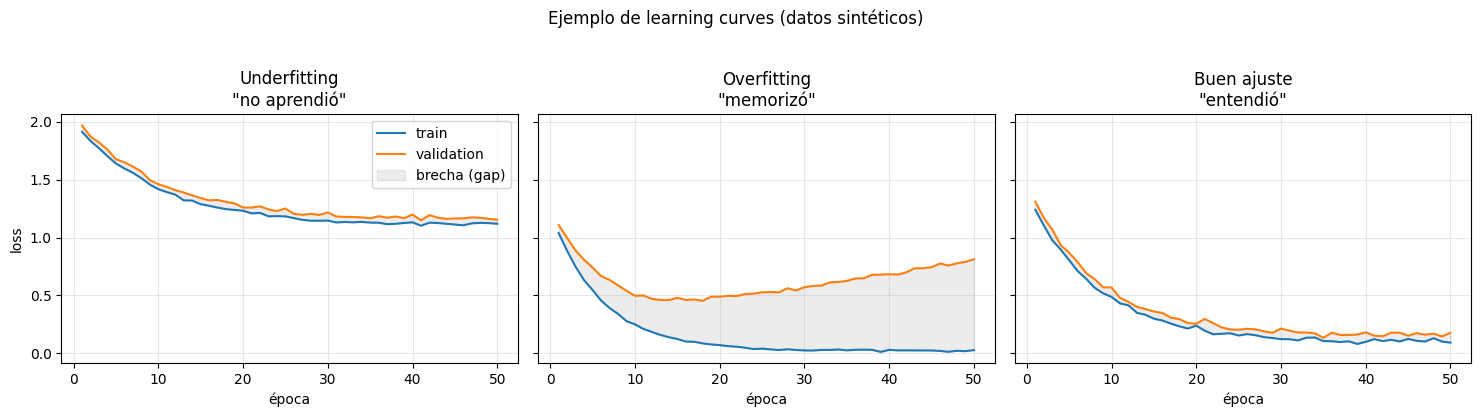

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Curvas SINTÉTICAS (inventadas) para aprender a leerlas
rng = np.random.default_rng(0)
ep = np.arange(1, 51)
noise = lambda s: rng.normal(0, s, size=ep.shape)

# 1) Underfitting: ambas curvas se quedan ALTAS y casi juntas
train_u = 1.10 + 0.90 * np.exp(-ep / 10) + noise(0.01)
val_u   = train_u + 0.05 + noise(0.01)

# 2) Overfitting: train baja casi a 0; val baja un rato y luego SUBE
train_o = 0.02 + 1.20 * np.exp(-ep / 6) + noise(0.005)
val_o   = 0.35 + 0.90 * np.exp(-ep / 6) + 0.012 * np.clip(ep - 12, 0, None) + noise(0.01)

# 3) Buen ajuste: ambas bajan, se estabilizan en un valor bajo y cerca una de otra
train_g = 0.10 + 1.30 * np.exp(-ep / 8) + noise(0.01)
val_g   = 0.16 + 1.30 * np.exp(-ep / 8) + noise(0.015)

curves = [
    ('Underfitting\n"no aprendió"', train_u, val_u),
    ('Overfitting\n"memorizó"',     train_o, val_o),
    ('Buen ajuste\n"entendió"',     train_g, val_g),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, tr, va) in zip(axes, curves):
    ax.plot(ep, tr, label='train')
    ax.plot(ep, va, label='validation')
    ax.fill_between(ep, tr, va, alpha=0.15, color='gray', label='brecha (gap)')
    ax.set_title(title)
    ax.set_xlabel('época')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('loss')
axes[0].legend()
plt.suptitle('Ejemplo de learning curves (datos sintéticos)', y=1.03)
plt.tight_layout()
plt.show()

### 🧐 Cómo leer las curvas (checklist de 3 preguntas)

Para cada experimento hazte estas tres preguntas, **en este orden**:

1. **¿Cómo está el rendimiento en *train*?** ¿La loss es baja y la accuracy alta? Si no, el modelo ni siquiera aprende los datos de entrenamiento → sospecha de **underfitting**.
2. **¿Qué tan grande es la brecha entre *train* y *validation*?** Si es grande → sospecha de **overfitting**.
3. **¿Qué hace la *val loss* a lo largo de las épocas?** Si baja y luego sube mientras la train loss sigue bajando → **overfitting** (el estudiante B empezó a memorizar). La línea punteada gris de nuestras gráficas marca la época con menor val loss.

Si train y validation son buenos y están cerca, y la val loss no sube → **modelo bueno**.

> 📝 *Nota:* la accuracy y la loss cuentan historias parecidas pero no idénticas. La **loss** es más sensible: a veces la accuracy de validation parece estable mientras la val loss ya está subiendo (el modelo se vuelve "demasiado seguro" de sus errores).

---
# 2. Configuración del entorno

Si estás en Colab o no tienes las librerías, descomenta la primera línea de la siguiente celda.

In [2]:
# !pip install torch torchvision pandas matplotlib

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Subset, random_split
from torchvision import datasets

SEED = 42

def set_seed(seed=SEED):
    """Fija las semillas para que los experimentos sean reproducibles."""
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"PyTorch {torch.__version__} | dispositivo: {DEVICE}")

PyTorch 2.14.1+cpu | dispositivo: cpu


---
# 3. Dataset: MNIST

**MNIST** contiene imágenes de 28×28 píxeles de dígitos escritos a mano (clases 0 a 9). Es fácil de cargar y procesar, ideal para estudiar MLPs.

Para que el **overfitting sea visible y los experimentos sean rápidos**, no usaremos las 60,000 imágenes de entrenamiento completas. Haremos lo siguiente:

- Tomaremos un **pool de 10,000 imágenes** al azar del set de entrenamiento oficial.
- En la **Sección 4** tú dividirás ese pool en **train (80 %)** y **validation (20 %)**.
- El set de **test oficial (10,000 imágenes)** se queda guardado y **solo se usará al final, en el Ejercicio 10**.

100%|██████████| 9.91M/9.91M [00:00<00:00, 22.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 609kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.19MB/s]


Pool: (10000, 1, 28, 28) | Test oficial: (10000, 1, 28, 28)
Muestras por clase en el pool: [993, 1074, 1016, 1042, 982, 914, 995, 1011, 1005, 968]


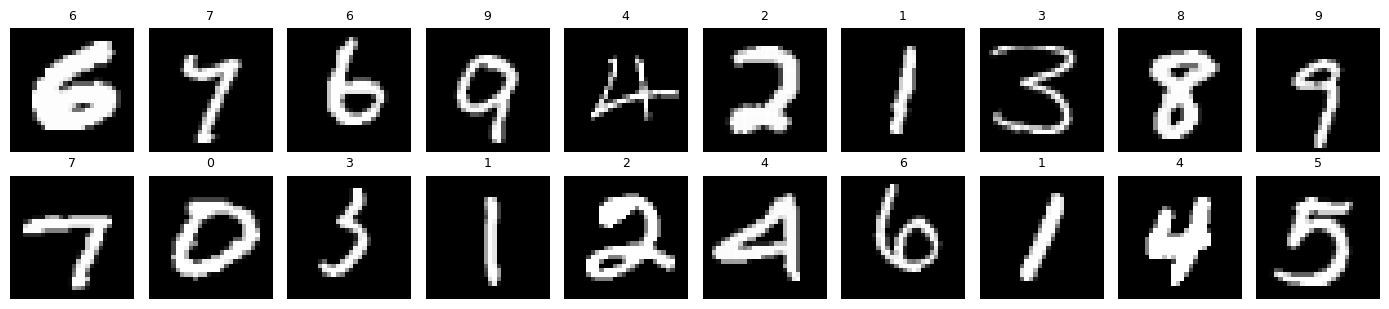

In [3]:
# Descarga (la primera vez) los datos oficiales de MNIST
full_train = datasets.MNIST(root='./data', train=True,  download=True)
full_test  = datasets.MNIST(root='./data', train=False, download=True)

MEAN, STD = 0.1307, 0.3081   # media y desviación estándar de MNIST

def to_tensors(mnist_ds, indices=None):
    """Convierte las imágenes a tensores normalizados con forma (N, 1, 28, 28)."""
    X = mnist_ds.data if indices is None else mnist_ds.data[indices]
    y = mnist_ds.targets if indices is None else mnist_ds.targets[indices]
    X = ((X.float() / 255.0) - MEAN) / STD
    return X.unsqueeze(1), y

# Pool de 10,000 imágenes elegidas al azar del set de entrenamiento oficial
POOL_SIZE = 10_000
g = torch.Generator().manual_seed(SEED)
pool_idx = torch.randperm(len(full_train), generator=g)[:POOL_SIZE]
X_pool, y_pool = to_tensors(full_train, pool_idx)
pool_ds = TensorDataset(X_pool, y_pool)

# Set de test oficial (NO lo toques hasta el Ejercicio 10)
X_test, y_test = to_tensors(full_test)
test_ds = TensorDataset(X_test, y_test)

print(f"Pool: {tuple(X_pool.shape)} | Test oficial: {tuple(X_test.shape)}")
print("Muestras por clase en el pool:", torch.bincount(y_pool).tolist())

# Vistazo a algunas imágenes
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_pool[i, 0], cmap='gray')
    ax.set_title(int(y_pool[i]), fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

---
# 4. Train / validation / test split (¡tu turno!)

## ¿Por qué dividir los datos?

Volvamos a nuestra analogía:

| Conjunto | En la analogía | Para qué sirve |
|---|---|---|
| **Train** | Los 100 ejercicios de práctica | El modelo **aprende** de estos datos (se ajustan los pesos). |
| **Validation** | El simulacro con ejercicios nuevos | Sirve para **diagnosticar** (under/overfitting) y **elegir hiperparámetros**. El modelo no se entrena con estos datos. |
| **Test** | El examen final | Se usa **una sola vez** al final para estimar el rendimiento real. Si lo usas para tomar decisiones, deja de ser un examen sorpresa. |

Si evaluáramos solo en train, el estudiante B (el que memoriza) parecería un genio. La validación nos permite **detectarlo**.

## Cómo hacer el split en PyTorch

La herramienta estándar es [`torch.utils.data.random_split`](https://pytorch.org/docs/stable/data.html#torch.utils.data.random_split). Recibe un dataset y una lista con el **tamaño** de cada parte (deben sumar exactamente el total), y devuelve objetos `Subset`:

```python
from torch.utils.data import random_split

n_train = int(0.8 * len(dataset))     # 80 % para entrenar
n_val   = len(dataset) - n_train      # el resto para validar (así la suma siempre es exacta)

train_part, val_part = random_split(
    dataset,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(42),   # para que el split sea reproducible
)
```

Puntos importantes:
- El split es **aleatorio** (los datos pueden venir ordenados por clase o por fecha, y no queremos sesgos).
- Fijamos una **semilla** para poder reproducir el mismo split.
- Train y validation **no deben compartir ninguna muestra** (si no, es como darle al estudiante las preguntas del examen).

**Referencias útiles:**
- [Documentación de `random_split`](https://pytorch.org/docs/stable/data.html#torch.utils.data.random_split)
- Alternativa con scikit-learn: [`sklearn.model_selection.train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) (permite `stratify=y` para mantener la proporción de clases).

Primero corre este **ejemplo guiado** con un dataset de juguete (ya funciona, solo léelo):

In [4]:
# --- EJEMPLO GUIADO (ya funciona; solo léelo y córrelo) ---
# Dataset de juguete: 100 muestras con 3 features y etiquetas 0/1
X_toy = torch.randn(100, 3)
y_toy = torch.randint(0, 2, (100,))
toy_ds = TensorDataset(X_toy, y_toy)

n_toy_train = int(0.8 * len(toy_ds))      # 80
n_toy_val   = len(toy_ds) - n_toy_train   # 20

toy_train, toy_val = random_split(
    toy_ds,
    [n_toy_train, n_toy_val],
    generator=torch.Generator().manual_seed(SEED),
)

print("Tamaños:", len(toy_train), len(toy_val))
print("Primeros índices de train:", toy_train.indices[:5])
print("¿Hay muestras en común?:", len(set(toy_train.indices) & set(toy_val.indices)) > 0)

Tamaños: 80 20
Primeros índices de train: [42, 96, 62, 98, 46]
¿Hay muestras en común?: False


## ✍️ Tu tarea

Divide `pool_ds` (10,000 muestras) en:
- `train_ds`: **80 %** → 8,000 muestras
- `val_ds`: **20 %** → 2,000 muestras

Completa los espacios `____` de la celda siguiente (mientras estén sin completar verás un `NameError`; es normal).

<details>
<summary>💡 Pista (haz clic si te atascas)</summary>

Sigue exactamente el ejemplo guiado: calcula `n_train` como el 80 % del total, `n_val` como el resto, y pásale a `random_split` el dataset a dividir y la lista `[n_train, n_val]`.
</details>

In [5]:
# --- TU TURNO ---
n_total = len(pool_ds)
n_train = int(0.8 * n_total)     # TODO: número de muestras de entrenamiento (80 % del total)
n_val   = n_total - n_train     # TODO: número de muestras de validación (el resto)

train_ds, val_ds = random_split(
    pool_ds,                                   # TODO: ¿qué dataset se divide?
    [n_train, n_val],                           # TODO: tamaños de cada parte
    generator=torch.Generator().manual_seed(SEED),
)

print(f"Train: {len(train_ds)} | Validation: {len(val_ds)} | Test (guardado): {len(test_ds)}")

Train: 8000 | Validation: 2000 | Test (guardado): 10000


In [6]:
# --- VERIFICACIÓN (no modificar) ---
assert len(train_ds) + len(val_ds) == len(pool_ds), "Train + validation debe sumar 10,000 muestras."
assert len(train_ds) == 8000 and len(val_ds) == 2000, "Se esperaban 8,000 muestras en train y 2,000 en validation."
assert len(set(train_ds.indices) & set(val_ds.indices)) == 0, "¡Train y validation comparten muestras!"
print("✅ Split correcto.")
print("Distribución de clases en train:     ", torch.bincount(y_pool[train_ds.indices]).tolist())
print("Distribución de clases en validation:", torch.bincount(y_pool[val_ds.indices]).tolist())

✅ Split correcto.
Distribución de clases en train:      [801, 879, 786, 837, 771, 718, 800, 817, 817, 774]
Distribución de clases en validation: [192, 195, 230, 205, 211, 196, 195, 194, 188, 194]


### 📝 Tus respuestas — Sección 4

**1. Explica con la analogía del estudiante: ¿por qué necesitamos un conjunto de validation además del de train?**
> Train es el libro de práctica. Validation es un simulacro con ejercicios nuevos que muestra si el estudiante puede aplicar lo aprendido a casos que todavía no ha visto.

**2. ¿Por qué NO debemos usar el conjunto de test para elegir hiperparámetros (learning rate, número de capas, etc.)?**
> Si pruebo varios hiperparámetros y elijo el que mejor sale en test, aprovecho las particularidades de ese conjunto. Reservarlo hasta el final permite estimar el rendimiento del modelo elegido en datos que quedaron fuera de todas las decisiones.

**3. ¿Por qué es importante que el split sea aleatorio (y no, por ejemplo, tomar las primeras 8,000 muestras para train y las últimas 2,000 para validation)? Pista: ¿qué pasaría si los datos vinieran ordenados por clase?**
> Un corte por posición puede dejar clases completas en una sola parte si las imágenes vienen ordenadas por dígito. La selección aleatoria reparte las muestras y reduce ese sesgo.

**4. (Reto opcional) ¿Qué significa "estratificar" un split y cuándo es especialmente útil?**
> Estratificar consiste en conservar aproximadamente la misma proporción de cada clase en las particiones. Es especialmente útil con clases poco frecuentes o conjuntos pequeños.

---
# 5. Código base (no modificar)

Esta sección contiene todo lo necesario para entrenar y graficar. **Ejecuta las celdas sin modificarlas.** Léelas con calma: es una buena oportunidad para entender cómo se arma un MLP y un loop de entrenamiento.

### Hiperparámetros disponibles

Todos los experimentos se definen con un diccionario de configuración, que se crea con `make_config(**cambios)`. Los valores **por defecto** (baseline) son:

| Hiperparámetro | Valor por defecto | Descripción |
|---|---|---|
| `hidden_sizes` | `[128, 64]` | Neuronas de cada capa oculta (arquitectura). |
| `activation` | `'relu'` | `'relu'`, `'tanh'`, `'leaky_relu'` o `'gelu'`. |
| `dropout` | `0.0` | Probabilidad de apagar neuronas durante el entrenamiento. |
| `batch_norm` | `False` | Si se usa Batch Normalization después de cada capa lineal. |
| `optimizer` | `'adam'` | `'adam'`, `'adamw'` o `'sgd'` (con momentum 0.9). |
| `lr` | `1e-3` | Learning rate. |
| `weight_decay` | `0.0` | Penalización L2 sobre los pesos. |
| `batch_size` | `64` | Tamaño del mini-batch. |
| `epochs` | `30` | Número de épocas. |
| `n_train` | `None` | Si es un entero, usa solo las primeras `n_train` muestras de train. |

> 💡 En cada época medimos la loss y la accuracy de **train** y de **validation** con el modelo en modo evaluación (sin dropout), para que las learning curves sean comparables.

In [7]:
class MLP(nn.Module):
    """Perceptrón multicapa configurable: [Linear -> (BatchNorm) -> Activación -> (Dropout)] x N -> Linear."""

    def __init__(self, input_dim=784, hidden_sizes=(128, 64), num_classes=10,
                 activation='relu', dropout=0.0, batch_norm=False):
        super().__init__()
        activations = {
            'relu': nn.ReLU,
            'tanh': nn.Tanh,
            'leaky_relu': nn.LeakyReLU,
            'gelu': nn.GELU,
        }
        if activation not in activations:
            raise ValueError(f"Activación desconocida: {activation}. Opciones: {list(activations)}")

        layers = [nn.Flatten()]            # (N, 1, 28, 28) -> (N, 784)
        prev = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev, h))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(activations[activation]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, num_classes))   # salida: logits de 10 clases
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(model):
    """Número de parámetros entrenables del modelo."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Prueba rápida de la arquitectura baseline
print(MLP())
print("Parámetros:", count_params(MLP()))

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Parámetros: 109386


In [8]:
# ---------- Configuración y entrenamiento ----------
BASE_CONFIG = dict(
    hidden_sizes=[128, 64],
    activation='relu',
    dropout=0.0,
    batch_norm=False,
    optimizer='adam',
    lr=1e-3,
    weight_decay=0.0,
    batch_size=64,
    epochs=30,
    n_train=None,
)

RESULTS = {}   # aquí se guardan los resultados de todos tus experimentos


def make_config(**changes):
    """Crea una configuración a partir del baseline, cambiando solo lo que indiques."""
    unknown = set(changes) - set(BASE_CONFIG)
    if unknown:
        raise ValueError(f"Hiperparámetros desconocidos: {unknown}. Válidos: {list(BASE_CONFIG)}")
    cfg = {k: (list(v) if isinstance(v, list) else v) for k, v in BASE_CONFIG.items()}
    cfg.update(changes)
    return cfg


def build_optimizer(model, cfg):
    name = cfg['optimizer'].lower()
    params = model.parameters()
    if name == 'adam':
        return torch.optim.Adam(params, lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    if name == 'adamw':
        return torch.optim.AdamW(params, lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    if name == 'sgd':
        return torch.optim.SGD(params, lr=cfg['lr'], momentum=0.9, weight_decay=cfg['weight_decay'])
    raise ValueError(f"Optimizador desconocido: {name}")


@torch.no_grad()
def evaluate(model, loader):
    """Devuelve (loss, accuracy) promedio sobre un DataLoader, con el modelo en modo evaluación."""
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE)
        logits = model(X)
        total_loss += F.cross_entropy(logits, y, reduction='sum').item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train_model(cfg, name, verbose=True):
    """Entrena un MLP con la configuración `cfg`.

    Guarda el historial en RESULTS[name] y devuelve (modelo, historial).
    El historial tiene: train_loss, val_loss, train_acc, val_acc (un valor por época).
    """
    if 'train_ds' not in globals() or 'val_ds' not in globals():
        raise RuntimeError("Primero completa la Sección 4 (train/validation split).")

    set_seed(SEED)   # misma semilla en cada experimento -> comparaciones justas

    train_data = train_ds if cfg['n_train'] is None else Subset(train_ds, range(cfg['n_train']))
    if len(train_data) < cfg['batch_size']:
        raise ValueError("n_train debe ser al menos igual al batch_size.")

    # drop_last=True evita un último batch de tamaño 1 (problemático para BatchNorm)
    train_loader = DataLoader(train_data, batch_size=cfg['batch_size'], shuffle=True, drop_last=True)
    train_eval_loader = DataLoader(train_data, batch_size=2000, shuffle=False)
    val_loader = DataLoader(val_ds, batch_size=2000, shuffle=False)

    model = MLP(hidden_sizes=cfg['hidden_sizes'], activation=cfg['activation'],
                dropout=cfg['dropout'], batch_norm=cfg['batch_norm']).to(DEVICE)
    optimizer = build_optimizer(model, cfg)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    t0 = time.time()

    for epoch in range(1, cfg['epochs'] + 1):
        model.train()
        for X, y in train_loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(X), y)
            loss.backward()
            optimizer.step()

        tr_loss, tr_acc = evaluate(model, train_eval_loader)
        va_loss, va_acc = evaluate(model, val_loader)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(va_acc)

        if verbose and (epoch == 1 or epoch % 5 == 0 or epoch == cfg['epochs']):
            print(f"[{name}] época {epoch:3d}/{cfg['epochs']} | "
                  f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")

    if verbose:
        print(f"Parámetros: {count_params(model):,} | tiempo: {time.time() - t0:.1f} s")

    RESULTS[name] = {'config': cfg, 'history': history}
    return model, history

In [9]:
# ---------- Gráficas y resúmenes ----------
def best_epoch(history):
    """Época (empezando en 1) con la menor validation loss."""
    vl = np.array(history['val_loss'], dtype=float)
    if np.all(np.isnan(vl)):
        return 1
    return int(np.nanargmin(vl)) + 1


def plot_learning_curves(history, title='Learning curves'):
    """Grafica loss y accuracy de train y validation. La línea gris marca la época con menor val loss."""
    epochs = range(1, len(history['train_loss']) + 1)
    b = best_epoch(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history['train_loss'], label='train')
    axes[0].plot(epochs, history['val_loss'], label='validation')
    axes[0].axvline(b, color='gray', linestyle='--', alpha=0.7, label=f'mín. val loss (época {b})')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('época')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history['train_acc'], label='train')
    axes[1].plot(epochs, history['val_acc'], label='validation')
    axes[1].axvline(b, color='gray', linestyle='--', alpha=0.7)
    axes[1].set_title('Accuracy')
    axes[1].set_xlabel('época')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def print_summary(history):
    """Imprime los números clave para diagnosticar (¡úsalos como evidencia!)."""
    tr_acc, va_acc = history['train_acc'][-1], history['val_acc'][-1]
    tr_loss, va_loss = history['train_loss'][-1], history['val_loss'][-1]
    b = best_epoch(history)
    print(f"Accuracy final -> train: {tr_acc:.4f} | val: {va_acc:.4f} | brecha (train - val): {100 * (tr_acc - va_acc):+.2f} pts")
    print(f"Loss final     -> train: {tr_loss:.4f} | val: {va_loss:.4f}")
    print(f"Mínimo de val loss: {history['val_loss'][b - 1]:.4f} en la época {b} de {len(history['val_loss'])}")


def compare_runs(names, title='Comparación de experimentos'):
    """Superpone las curvas de varios experimentos (punteada = train, continua = validation)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for i, name in enumerate(names):
        h = RESULTS[name]['history']
        ep = range(1, len(h['train_loss']) + 1)
        c = f'C{i}'
        axes[0].plot(ep, h['train_loss'], color=c, linestyle='--', alpha=0.8)
        axes[0].plot(ep, h['val_loss'], color=c, label=name)
        axes[1].plot(ep, h['train_acc'], color=c, linestyle='--', alpha=0.8)
        axes[1].plot(ep, h['val_acc'], color=c, label=name)
    axes[0].set_title('Loss  (punteada = train, continua = validation)')
    axes[1].set_title('Accuracy  (punteada = train, continua = validation)')
    for ax in axes:
        ax.set_xlabel('época')
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def results_table(prefix=None):
    """Tabla con los resultados finales de los experimentos (opcionalmente filtrados por prefijo)."""
    rows = []
    for name, r in RESULTS.items():
        if prefix and not name.startswith(prefix):
            continue
        h = r['history']
        rows.append({
            'experimento': name,
            'train_acc': h['train_acc'][-1],
            'val_acc': h['val_acc'][-1],
            'brecha_acc_pts': 100 * (h['train_acc'][-1] - h['val_acc'][-1]),
            'train_loss': h['train_loss'][-1],
            'val_loss': h['val_loss'][-1],
            'mejor_epoca': best_epoch(h),
            'min_val_loss': float(np.nanmin(h['val_loss'])) if not np.all(np.isnan(h['val_loss'])) else float('nan'),
        })
    return pd.DataFrame(rows).set_index('experimento').round(4)


print("✅ Código base cargado. Uso básico:")
print("   cfg = make_config(dropout=0.3)")
print("   model, hist = train_model(cfg, 'mi_experimento')")
print("   plot_learning_curves(hist, 'Mi experimento'); print_summary(hist)")

✅ Código base cargado. Uso básico:
   cfg = make_config(dropout=0.3)
   model, hist = train_model(cfg, 'mi_experimento')
   plot_learning_curves(hist, 'Mi experimento'); print_summary(hist)


---
# 6. Ejercicios

En cada ejercicio escribirás tu **diagnóstico** con esta plantilla:

> **Diagnóstico:** _Underfitting_ / _Overfitting_ / _Modelo bueno_ (escoge uno)
> **Evidencia numérica:** valores de train/val y brecha
> **Respuestas y conclusión**

Recuerda el checklist: (1) ¿cómo está train? (2) ¿qué tan grande es la brecha? (3) ¿qué hace la val loss con las épocas?

## Ejercicio 1 — Baseline: tu punto de referencia

**Contexto:** antes de cambiar cosas necesitamos un punto de partida. La arquitectura baseline es `784 → 128 → 64 → 10` con ReLU, Adam (lr = 1e-3), batch de 64 y 30 épocas, sin ninguna regularización.

**Qué hacer:** ejecuta la celda sin modificarla. Anota los números: serán tu referencia en los demás ejercicios.

{'hidden_sizes': [128, 64], 'activation': 'relu', 'dropout': 0.0, 'batch_norm': False, 'optimizer': 'adam', 'lr': 0.001, 'weight_decay': 0.0, 'batch_size': 64, 'epochs': 30, 'n_train': None}
[ex1_baseline] época   1/30 | train loss 0.3098 acc 0.9095 | val loss 0.3348 acc 0.9000
[ex1_baseline] época   5/30 | train loss 0.0811 acc 0.9781 | val loss 0.1824 acc 0.9525
[ex1_baseline] época  10/30 | train loss 0.0186 acc 0.9968 | val loss 0.2052 acc 0.9480
[ex1_baseline] época  15/30 | train loss 0.0030 acc 1.0000 | val loss 0.2087 acc 0.9550
[ex1_baseline] época  20/30 | train loss 0.0010 acc 1.0000 | val loss 0.2241 acc 0.9565
[ex1_baseline] época  25/30 | train loss 0.0005 acc 1.0000 | val loss 0.2372 acc 0.9560
[ex1_baseline] época  30/30 | train loss 0.0003 acc 1.0000 | val loss 0.2503 acc 0.9565
Parámetros: 109,386 | tiempo: 17.4 s


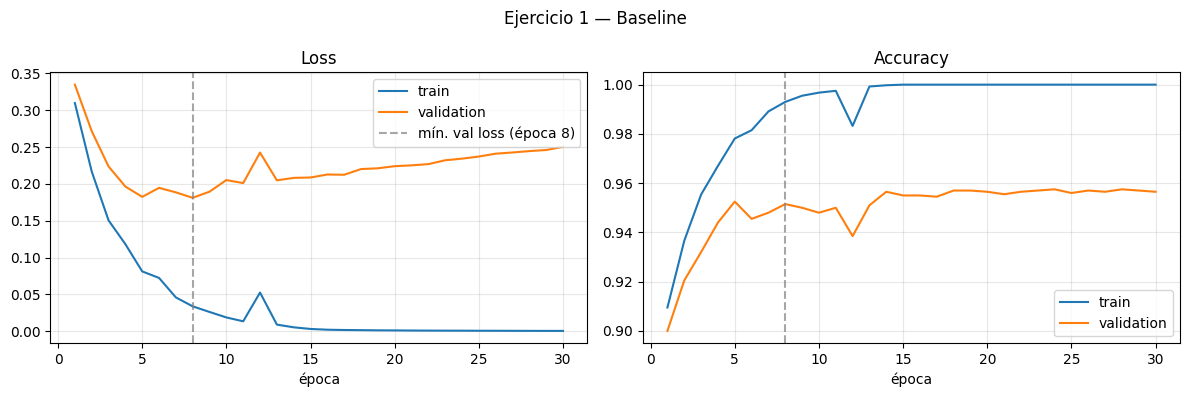

Accuracy final -> train: 1.0000 | val: 0.9565 | brecha (train - val): +4.35 pts
Loss final     -> train: 0.0003 | val: 0.2503
Mínimo de val loss: 0.1811 en la época 8 de 30


In [10]:
cfg = make_config()      # todos los valores por defecto
print(cfg)

model, hist = train_model(cfg, 'ex1_baseline')
plot_learning_curves(hist, 'Ejercicio 1 — Baseline')
print_summary(hist)

**Preguntas:**
1. ¿Qué accuracy tiene el modelo en train y en validation? ¿Qué tan grande es la brecha?
2. ¿La val loss baja durante todas las épocas o hay un punto a partir del cual sube? ¿En qué época?
3. Usando la analogía de los estudiantes, ¿a cuál se parece este modelo?

### 📝 Tus respuestas — Ejercicio 1

**Diagnóstico:** _(escribe uno: Underfitting / Overfitting / Modelo bueno)_ → Overfitting.

**Evidencia numérica:**
> Al final, accuracy train/val 100,00 % / 95,60 %, brecha +4,40 pp, loss train/val 0,0003 / 0,2515. El mínimo de val loss fue 0,1812 (época 8).

**Respuestas:**
1. Train llegó a 100,00 % y validation a 95,60 %. La brecha fue de +4,40 pp.
2. El mínimo de pérdida de validación fue 0,1812 (época 8) y terminó en 0,2515.
3. El estudiante B en las últimas épocas. Tiene un buen desempeño en el simulacro, pero su error de validación aumenta después de su punto óptimo mientras sigue mejorando en la práctica.

**Conclusión (2-3 líneas):**
> El baseline aprende bien los ejemplos de train. Para decidir cuándo parar me guío por la pérdida de validación, que detecta cambios que la accuracy puede pasar por alto.

---
## Ejercicio 2 — Capacidad insuficiente (¿cómo se ve el underfitting?)

**Contexto:** la *capacidad* de un modelo es qué tan complejas son las funciones que puede representar. Con muy pocas neuronas, el modelo tiene que comprimir toda la información de la imagen en muy pocos números.

**Parte A — Ya está dado.** Entrenamos un MLP con **una sola capa oculta de 2 neuronas**.

[ex2_underfit] época   1/30 | train loss 1.9971 acc 0.1779 | val loss 2.0114 acc 0.1780
[ex2_underfit] época   5/30 | train loss 1.5032 acc 0.4644 | val loss 1.5192 acc 0.4580
[ex2_underfit] época  10/30 | train loss 1.2669 acc 0.5489 | val loss 1.2825 acc 0.5540
[ex2_underfit] época  15/30 | train loss 1.1430 acc 0.6296 | val loss 1.1790 acc 0.6125
[ex2_underfit] época  20/30 | train loss 1.0826 acc 0.6388 | val loss 1.1302 acc 0.6215
[ex2_underfit] época  25/30 | train loss 1.0399 acc 0.6544 | val loss 1.0939 acc 0.6325
[ex2_underfit] época  30/30 | train loss 1.0136 acc 0.6576 | val loss 1.0735 acc 0.6380
Parámetros: 1,600 | tiempo: 9.9 s
Parámetros: 1600


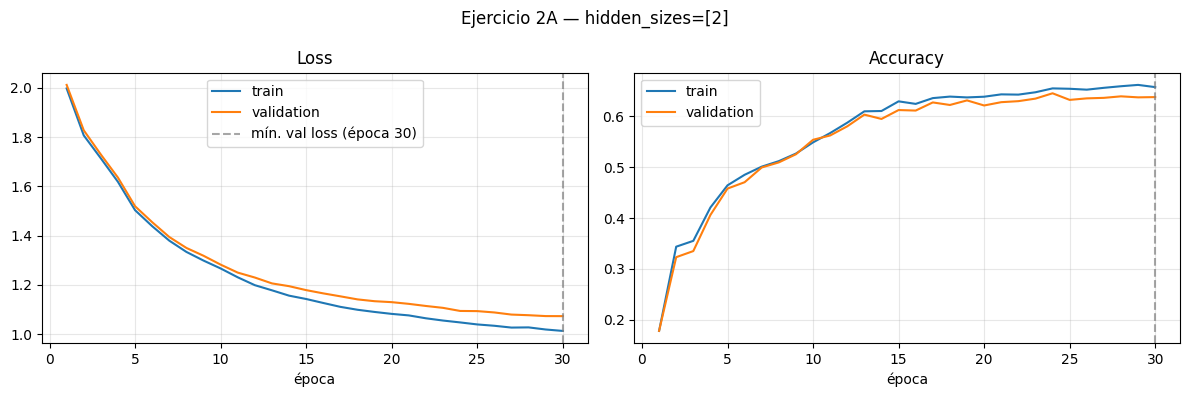

Accuracy final -> train: 0.6576 | val: 0.6380 | brecha (train - val): +1.96 pts
Loss final     -> train: 1.0136 | val: 1.0735
Mínimo de val loss: 1.0735 en la época 30 de 30


In [11]:
cfg = make_config(hidden_sizes=[2])    # una capa oculta con solo 2 neuronas
model, hist = train_model(cfg, 'ex2_underfit')
print("Parámetros:", count_params(model))
plot_learning_curves(hist, 'Ejercicio 2A — hidden_sizes=[2]')
print_summary(hist)

**Parte B — Tu cambio.** ¿Cuántas neuronas necesita el modelo para que el problema desaparezca? Modifica la lista `sizes` (marcada con `TODO`) y ejecuta la celda.

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex2_h4,0.8674,0.8515,1.5875,0.4409,0.5668,29,0.5601
ex2_h8,0.9412,0.8945,4.6750,0.2110,0.3818,20,0.3700
ex2_h16,0.9772,0.9200,5.7250,0.0893,0.3001,20,0.2761
ex2_h64,1.0000,0.9490,5.1000,0.0028,0.2287,13,0.1814


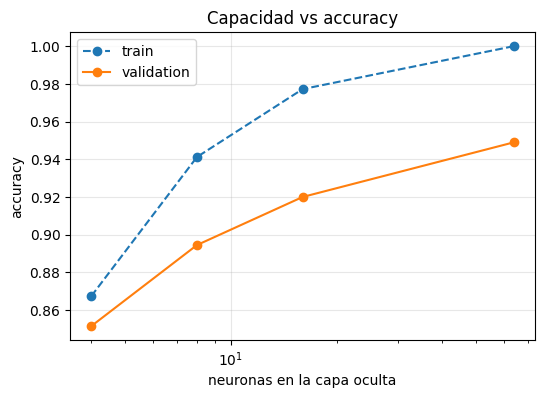

In [12]:
sizes = [4, 8, 16, 64]    # TODO: prueba otros tamaños (p. ej. agrega 8 o 256)
sizes = sorted(sizes)

for s in sizes:
    train_model(make_config(hidden_sizes=[s]), f'ex2_h{s}', verbose=False)

names = [f'ex2_h{s}' for s in sizes]
tab = results_table().loc[names]
display(tab)

plt.figure(figsize=(6, 4))
plt.plot(sizes, tab['train_acc'], 'o--', label='train')
plt.plot(sizes, tab['val_acc'], 'o-', label='validation')
plt.xscale('log')
plt.xlabel('neuronas en la capa oculta')
plt.ylabel('accuracy')
plt.title('Capacidad vs accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Preguntas:**
1. En la Parte A, ¿qué accuracy tiene el modelo en train? ¿Y en validation? ¿Cómo es la brecha?
2. ¿Por qué decimos que este modelo no está aprendiendo "ni siquiera lo básico"? ¿A cuál estudiante de la analogía se parece?
3. En la Parte B, ¿a partir de qué tamaño deja de haber underfitting? ¿Cómo lo decides con los números?
4. ¿Qué ocurre con la brecha train-val conforme crece la capacidad?

### 📝 Tus respuestas — Ejercicio 2

**Diagnóstico Parte A (`hidden_sizes=[2]`):** _(Underfitting / Overfitting / Modelo bueno)_ → Underfitting.

**Diagnóstico Parte B (tamaños probados):** _(escribe uno por cada tamaño)_
| tamaño | diagnóstico | evidencia |
|---|---|---|
| 4 | Underfitting | accuracy train/val 86,74 % / 85,15 %, brecha +1,59 pp, loss train/val 0,4409 / 0,5668 |
| 8 | Overfitting leve | accuracy train/val 94,12 % / 89,45 %, brecha +4,68 pp, loss train/val 0,2110 / 0,3818 |
| 16 | Overfitting | accuracy train/val 97,72 % / 92,00 %, brecha +5,72 pp, loss train/val 0,0893 / 0,3001 |
| 64 | Overfitting | accuracy train/val 100,00 % / 94,90 %, brecha +5,10 pp, loss train/val 0,0028 / 0,2286 |

**Evidencia numérica (Parte A):**
> Al final, accuracy train/val 65,76 % / 63,80 %, brecha +1,96 pp, loss train/val 1,0136 / 1,0735.

**Respuestas:**
1. Train 65,76 %, validation 63,80 % y brecha de +1,96 pp.
2. Las dos accuracies son bajas para MNIST. Se parece al estudiante A, que todavía comete muchos errores en los ejercicios que ya practicó.
3. Con 64 neuronas ambos conjuntos superaron el 93 % en esta comparación. Con 8 neuronas train ya superó el 93 % pero validation quedó por debajo del 90 %, señal de que ya cabía aprender más y la generalización aún era limitada. La evidencia con 64 fue accuracy train/val 100,00 % / 94,90 %, brecha +5,10 pp, loss train/val 0,0028 / 0,2286.
4. Para 4, 8, 16 y 64 neuronas, las brechas finales fueron +1,59 pp, +4,68 pp, +5,72 pp, +5,10 pp, respectivamente. La brecha se amplía en las redes con mayor capacidad de esta comparación.

**Conclusión (2-3 líneas):**
> Con dos neuronas faltaba capacidad para representar los dígitos. Subir a 64 mejoró ambos conjuntos. Seguir aumentando la capacidad puede ampliar la brecha.

---
## Ejercicio 3 — Capacidad excesiva (¿cómo se ve el overfitting?)

**Contexto:** ahora vamos al extremo contrario. Usaremos un modelo **mucho más grande** (3 capas ocultas de 1024 neuronas) con solo 8,000 imágenes de entrenamiento. Es como darle al estudiante B una memoria enorme y pocos ejercicios.

**Qué hacer:** ejecuta la celda (puede tardar 1-2 minutos en CPU). Requiere haber corrido el Ejercicio 1 para la comparación.

[ex3_big] época   1/30 | train loss 0.2290 acc 0.9264 | val loss 0.2772 acc 0.9225
[ex3_big] época   5/30 | train loss 0.0810 acc 0.9752 | val loss 0.2467 acc 0.9380
[ex3_big] época  10/30 | train loss 0.0239 acc 0.9931 | val loss 0.2271 acc 0.9535
[ex3_big] época  15/30 | train loss 0.0221 acc 0.9945 | val loss 0.2511 acc 0.9525
[ex3_big] época  20/30 | train loss 0.0076 acc 0.9980 | val loss 0.2184 acc 0.9640
[ex3_big] época  25/30 | train loss 0.0028 acc 0.9992 | val loss 0.2453 acc 0.9620
[ex3_big] época  30/30 | train loss 0.0000 acc 1.0000 | val loss 0.3204 acc 0.9640
Parámetros: 2,913,290 | tiempo: 251.0 s
Parámetros: 2,913,290


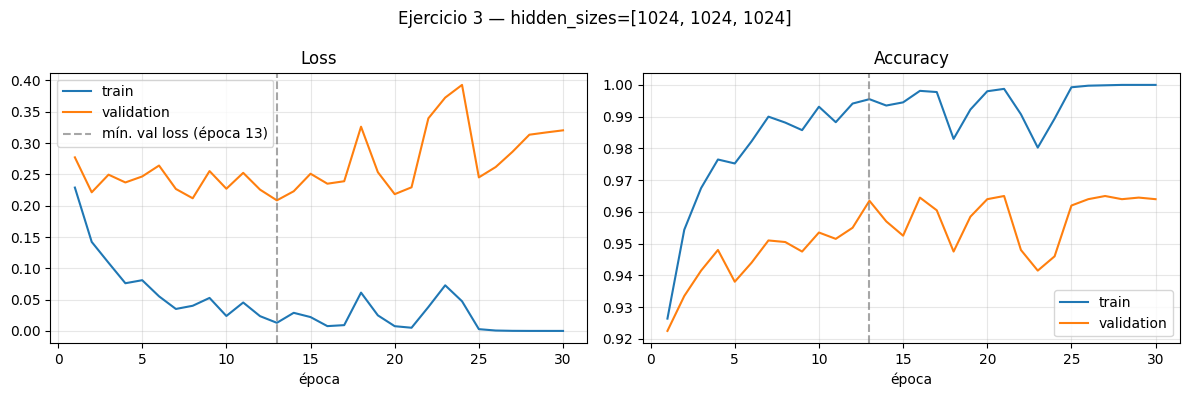

Accuracy final -> train: 1.0000 | val: 0.9640 | brecha (train - val): +3.60 pts
Loss final     -> train: 0.0000 | val: 0.3204
Mínimo de val loss: 0.2085 en la época 13 de 30


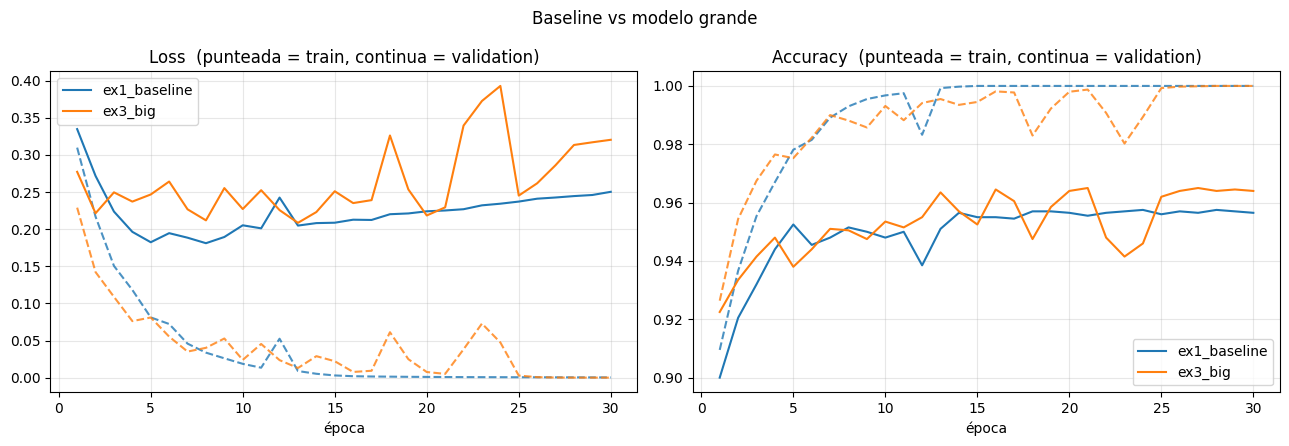

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex1_baseline,1.0000,0.9565,4.3500,0.0003,0.2503,8,0.1811
ex2_underfit,0.6576,0.6380,1.9625,1.0136,1.0735,30,1.0735
ex2_h4,0.8674,0.8515,1.5875,0.4409,0.5668,29,0.5601
ex2_h8,0.9412,0.8945,4.6750,0.2110,0.3818,20,0.3700
ex2_h16,0.9772,0.9200,5.7250,0.0893,0.3001,20,0.2761
ex2_h64,1.0000,0.9490,5.1000,0.0028,0.2287,13,0.1814
ex3_big,1.0000,0.9640,3.6000,0.0000,0.3204,13,0.2085


In [13]:
cfg = make_config(hidden_sizes=[1024, 1024, 1024])
model, hist = train_model(cfg, 'ex3_big')
print("Parámetros:", f"{count_params(model):,}")
plot_learning_curves(hist, 'Ejercicio 3 — hidden_sizes=[1024, 1024, 1024]')
print_summary(hist)

# Comparación con el baseline
compare_runs(['ex1_baseline', 'ex3_big'], 'Baseline vs modelo grande')
display(results_table('ex'))

**Preguntas:**
1. Compara con el baseline: ¿cambió la train accuracy? ¿Y la val accuracy? ¿Y la brecha?
2. ¿Qué pasa con la **val loss** a medida que avanzan las épocas, comparado con la train loss? ¿En qué época está su mínimo?
3. ¿Por qué un modelo con más parámetros puede "memorizar" más fácilmente un dataset pequeño? Explícalo con la analogía.
4. Compara la val accuracy final con la **época en la que la val loss fue mínima** (línea gris). Aunque la accuracy final no empeore, ¿qué te dice la val loss sobre lo que pasó después de esa época? ¿Por qué la accuracy puede "esconder" un overfitting que la loss sí muestra?

### 📝 Tus respuestas — Ejercicio 3

**Diagnóstico:** _(Underfitting / Overfitting / Modelo bueno)_ → Overfitting.

**Evidencia numérica:**
> Red grande, accuracy train/val 99,92 % / 96,30 %, brecha +3,63 pp, loss train/val 0,0029 / 0,2772. Baseline, accuracy train/val 100,00 % / 95,60 %, brecha +4,40 pp, loss train/val 0,0003 / 0,2515. Mínimo de val loss de la red grande, 0,1848 (época 3).

**Respuestas:**
1. El baseline tuvo 100,00 % / 95,60 % y brecha de +4,40 pp. La red grande obtuvo 99,92 % / 96,30 % y brecha de +3,63 pp.
2. La pérdida de train terminó en 0,0029. La de validación bajó hasta 0,1848 (época 3) y luego acabó en 0,2772.
3. Una red con más parámetros tiene más libertad para representar detalles de imágenes particulares. El estudiante B podría recordar los ejercicios concretos de un libro corto y aun así equivocarse en los del simulacro.
4. La accuracy de validación fue 95,35 % en la época de menor pérdida y 96,30 % al final. La accuracy solo cuenta aciertos. La entropía cruzada además penaliza que el modelo dé una probabilidad muy baja a la clase correcta.

**Conclusión (2-3 líneas):**
> Una red ancha puede conseguir una accuracy de entrenamiento casi perfecta y aun así predecir con demasiada confianza algunos dígitos nuevos. Comparar ambas pérdidas revela ese deterioro.

---
## Ejercicio 4 — ¿Cuántas épocas son demasiadas? (early stopping manual)

**Contexto:** el overfitting no solo depende del tamaño del modelo, también del **tiempo de entrenamiento**. El estudiante B memoriza más cuanto más repasa el mismo libro de ejercicios. Lo ideal es **parar cuando la val loss deja de mejorar** (*early stopping*).

Una versión automática de early stopping se ve así (solo para que la conozcas, no la ejecutes):

```python
best_val, patience, wait = float('inf'), 5, 0
for epoch in range(max_epochs):
    train_one_epoch(...)
    val_loss = evaluate(...)
    if val_loss < best_val:
        best_val, wait = val_loss, 0      # mejoró: guardamos y seguimos
    else:
        wait += 1                         # no mejoró
        if wait >= patience:              # tras 5 épocas sin mejorar, paramos
            break
```

**Parte A — Ya está dado.** Entrenamos el baseline durante **100 épocas**.

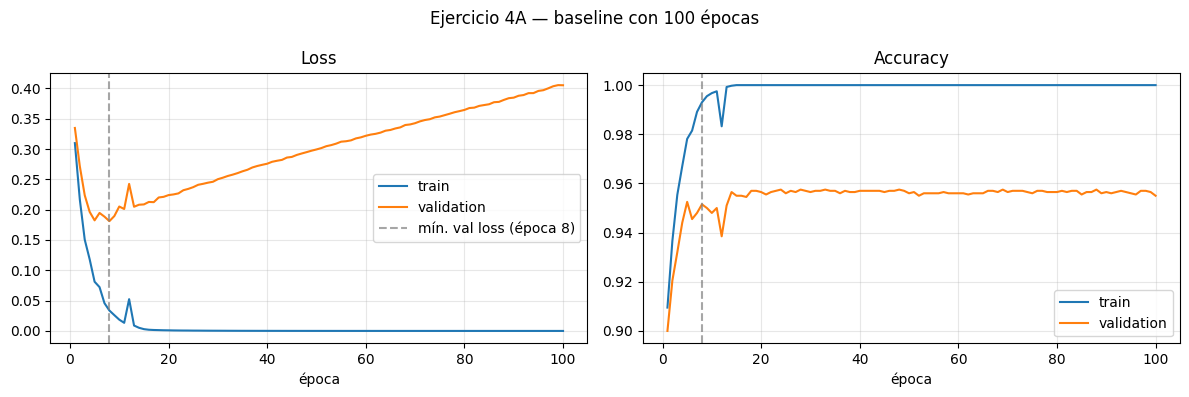

Accuracy final -> train: 1.0000 | val: 0.9550 | brecha (train - val): +4.50 pts
Loss final     -> train: 0.0000 | val: 0.4052
Mínimo de val loss: 0.1811 en la época 8 de 100


In [14]:
cfg = make_config(epochs=100)
model, hist = train_model(cfg, 'ex4_100ep', verbose=False)
plot_learning_curves(hist, 'Ejercicio 4A — baseline con 100 épocas')
print_summary(hist)

**Parte B — Tu cambio.** Mira la gráfica de arriba y la línea "Mínimo de val loss ... en la época X". Reentrena el mismo modelo **parando en esa época** cambiando el valor marcado con `TODO`.

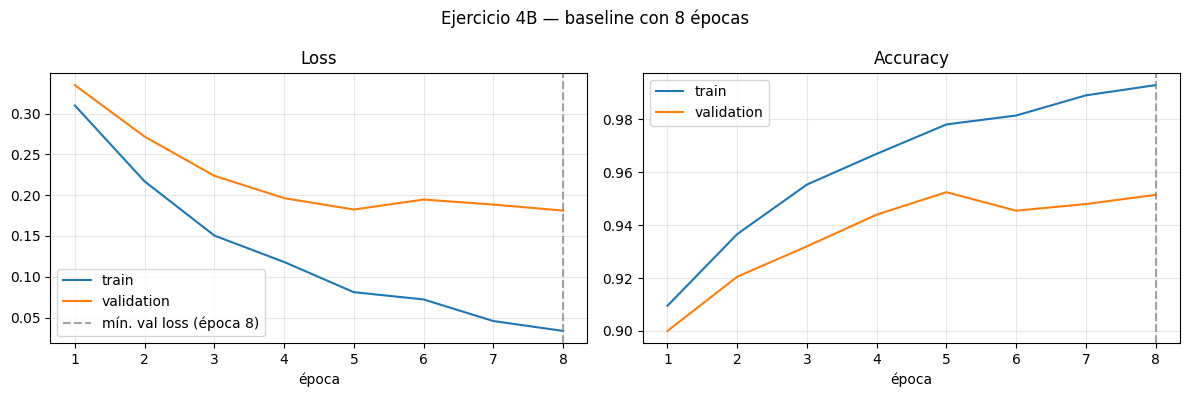

Accuracy final -> train: 0.9930 | val: 0.9515 | brecha (train - val): +4.15 pts
Loss final     -> train: 0.0337 | val: 0.1811
Mínimo de val loss: 0.1811 en la época 8 de 8


,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex4_100ep,1.000,0.9550,4.50,0.0000,0.4052,8,0.1811
ex4_early,0.993,0.9515,4.15,0.0337,0.1811,8,0.1811


In [15]:
BEST_EPOCH = best_epoch(RESULTS['ex4_100ep']['history'])    # TODO: reemplaza por la época del mínimo de val loss que observaste en la Parte A

cfg = make_config(epochs=BEST_EPOCH)
model, hist = train_model(cfg, 'ex4_early', verbose=False)
plot_learning_curves(hist, f'Ejercicio 4B — baseline con {BEST_EPOCH} épocas')
print_summary(hist)
display(results_table('ex4_'))

**Preguntas:**
1. En la Parte A, ¿en qué época está el mínimo de la val loss? ¿Qué pasa con la val loss y la train loss después de esa época?
2. ¿Qué pasa con la **val accuracy** después de ese punto? ¿Se nota tanto como en la loss?
3. Compara los resultados finales de la Parte A y la Parte B (val loss y val accuracy). ¿Cuál es mejor? ¿Entrenar más épocas siempre ayuda?
4. ¿Qué ventaja tiene early stopping automático (con `patience`) frente a elegir la época a mano?

### 📝 Tus respuestas — Ejercicio 4

**Diagnóstico Parte A (100 épocas):** _(Underfitting / Overfitting / Modelo bueno)_ → Overfitting.

**Diagnóstico Parte B (parando en tu época):** _(Underfitting / Overfitting / Modelo bueno)_ → Modelo bueno.

**Evidencia numérica:**
> A (100 épocas), accuracy train/val 100,00 % / 95,55 %, brecha +4,45 pp, loss train/val 0,0000 / 0,4078. B (8 épocas), accuracy train/val 99,30 % / 95,15 %, brecha +4,15 pp, loss train/val 0,0337 / 0,1812.

**Respuestas:**
1. El mínimo fue 0,1812 (época 8). De ahí al final la pérdida de validación acabó en 0,4078 y la de train pasó de 0,0337 a 0,0000.
2. La accuracy de validación pasó de 95,15 % en el mínimo de pérdida a 95,55 % al final. Su cambio fue menor que el de la pérdida.
3. B obtuvo loss 0,1812 y accuracy 95,15 %. A obtuvo loss 0,4078 y accuracy 95,55 %. Prefiero B por la pérdida, que en este ejercicio es el criterio para decidir cuándo parar.
4. Con patience se toleran algunas épocas sin mejora por las fluctuaciones normales. Al agotarse ese margen se detiene el entrenamiento y se recuperan los pesos de la mejor época, sin tener que fijarla a mano por adelantado.

**Conclusión (2-3 líneas):**
> Parar en la época 8 conservó el mejor valor observado de la pérdida de validación. Las épocas extra permitieron seguir ajustando train, pero empeoraron la pérdida en ejemplos nuevos.

---
## Ejercicio 5 — Dropout: un estudiante que no puede memorizar

**Contexto:** **Dropout** apaga aleatoriamente una fracción de las neuronas en cada paso de entrenamiento. Obliga a la red a no depender de neuronas concretas, y es como obligar al estudiante a estudiar sin poder apoyarse siempre en las mismas "pistas": le cuesta más memorizar.

**Parte A — Ya está dado.** Usamos el mismo modelo grande del Ejercicio 3, pero con `dropout=0.5`.

[ex5_dropout0.5] época   1/30 | train loss 0.3167 acc 0.8974 | val loss 0.3607 acc 0.8850
[ex5_dropout0.5] época   5/30 | train loss 0.0861 acc 0.9766 | val loss 0.1708 acc 0.9505
[ex5_dropout0.5] época  10/30 | train loss 0.0376 acc 0.9884 | val loss 0.1800 acc 0.9540
[ex5_dropout0.5] época  15/30 | train loss 0.0490 acc 0.9860 | val loss 0.2224 acc 0.9580
[ex5_dropout0.5] época  20/30 | train loss 0.0291 acc 0.9910 | val loss 0.2512 acc 0.9410
[ex5_dropout0.5] época  25/30 | train loss 0.0166 acc 0.9950 | val loss 0.2148 acc 0.9610
[ex5_dropout0.5] época  30/30 | train loss 0.0152 acc 0.9958 | val loss 0.2245 acc 0.9595
Parámetros: 2,913,290 | tiempo: 250.9 s


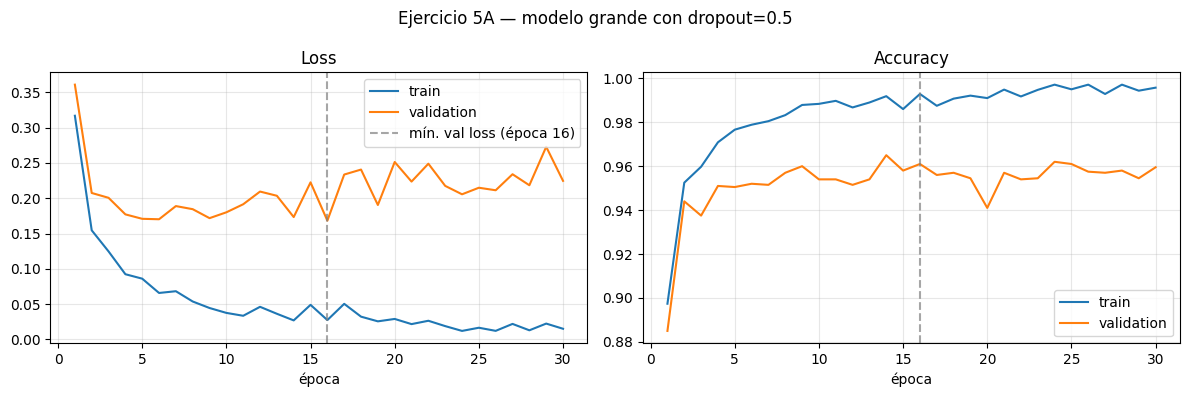

Accuracy final -> train: 0.9958 | val: 0.9595 | brecha (train - val): +3.63 pts
Loss final     -> train: 0.0152 | val: 0.2245
Mínimo de val loss: 0.1682 en la época 16 de 30


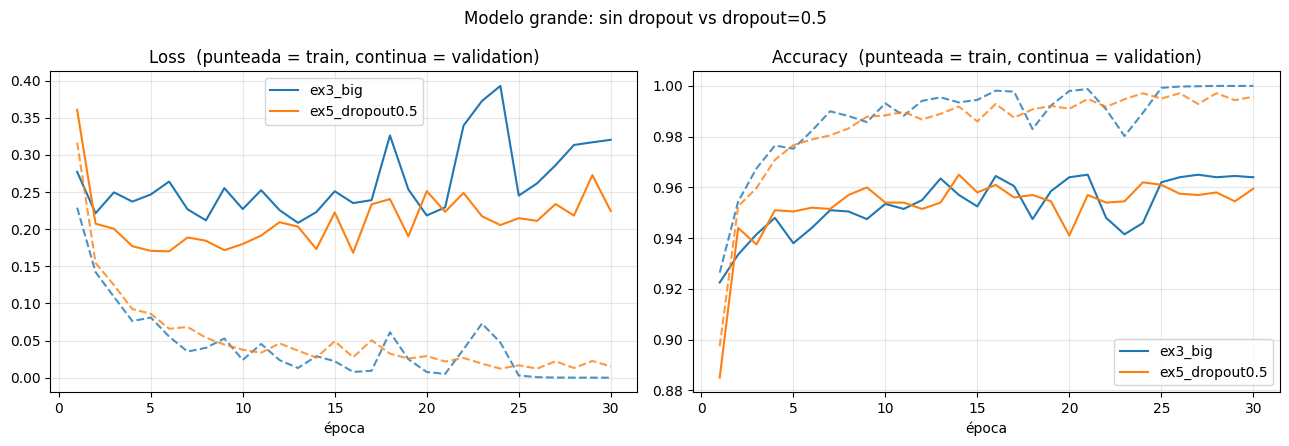

In [16]:
cfg = make_config(hidden_sizes=[1024, 1024, 1024], dropout=0.5)
model, hist = train_model(cfg, 'ex5_dropout0.5')
plot_learning_curves(hist, 'Ejercicio 5A — modelo grande con dropout=0.5')
print_summary(hist)

compare_runs(['ex3_big', 'ex5_dropout0.5'], 'Modelo grande: sin dropout vs dropout=0.5')

**Parte B — Tu cambio.** Prueba otro valor de dropout (por ejemplo `0.8`, que es muy agresivo, o `0.1`, que es suave). Cambia el valor marcado con `TODO`.

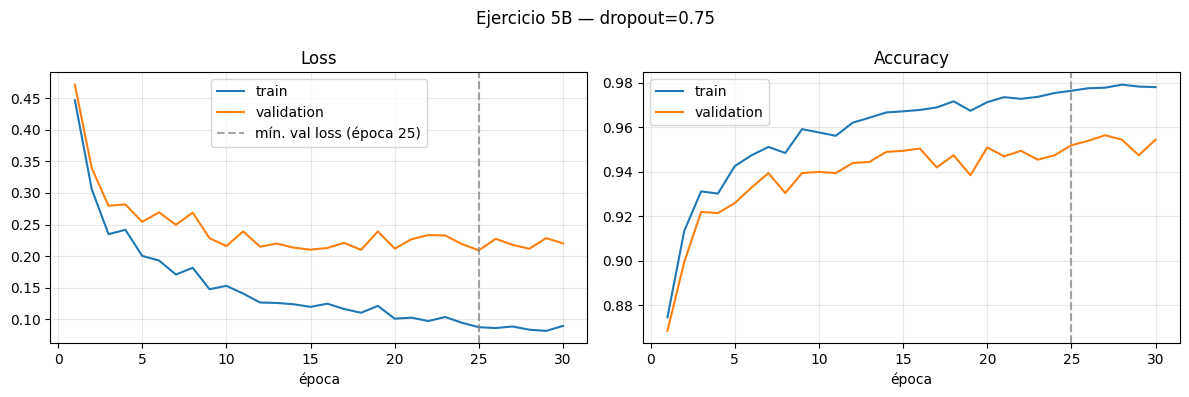

Accuracy final -> train: 0.9781 | val: 0.9545 | brecha (train - val): +2.36 pts
Loss final     -> train: 0.0897 | val: 0.2202
Mínimo de val loss: 0.2093 en la época 25 de 30


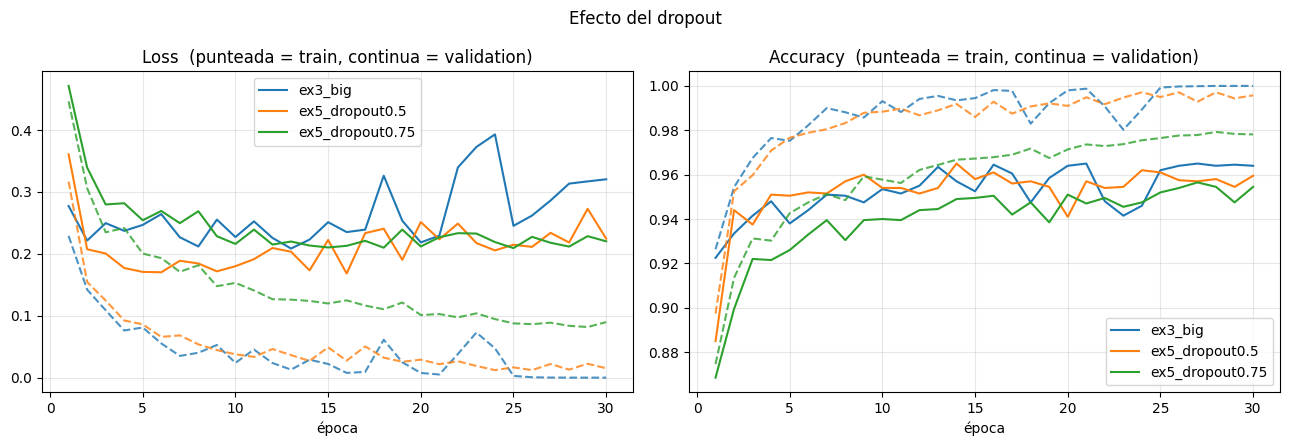

In [17]:
dropout_b = 0.75    # TODO: prueba otro valor entre 0.1 y 0.9

cfg = make_config(hidden_sizes=[1024, 1024, 1024], dropout=dropout_b)
model, hist = train_model(cfg, f'ex5_dropout{dropout_b}', verbose=False)
plot_learning_curves(hist, f'Ejercicio 5B — dropout={dropout_b}')
print_summary(hist)
compare_runs(['ex3_big', 'ex5_dropout0.5', f'ex5_dropout{dropout_b}'], 'Efecto del dropout')

**Preguntas:**
1. ¿Cómo cambió la brecha train-val al usar `dropout=0.5` respecto al Ejercicio 3?
2. ¿Cómo cambió el comportamiento de la val loss en las últimas épocas?
3. En la Parte B, ¿el valor que probaste mejora o empeora el resultado? ¿Puede una regularización **excesiva** producir el problema contrario (underfitting)? Justifica con tus números.
4. ¿Por qué usamos `model.eval()` al medir train y validation (es decir, por qué se desactiva el dropout)?

### 📝 Tus respuestas — Ejercicio 5

**Diagnóstico Parte A (dropout=0.5):** _(Underfitting / Overfitting / Modelo bueno)_ → Overfitting leve.

**Diagnóstico Parte B (tu valor de dropout = 0.75):** _(Underfitting / Overfitting / Modelo bueno)_ → Modelo bueno.

**Evidencia numérica:**
> Dropout 0,5, accuracy train/val 99,51 % / 96,20 %, brecha +3,31 pp, loss train/val 0,0171 / 0,2238. Dropout 0,75, accuracy train/val 97,84 % / 94,85 %, brecha +2,99 pp, loss train/val 0,0874 / 0,2257.

**Respuestas:**
1. Con 0,5 la brecha bajó de +3,63 pp a +3,31 pp al comparar la misma arquitectura.
2. La pérdida final con 0,5 fue 0,2238, con mínimo de 0,1655 (época 15). Sin dropout, la pérdida llegó a 0,2772 al cierre.
3. Con 0,75, la accuracy de train fue 97,84 % frente a 99,51 % con 0,5. En validation obtuve 94,85 % frente a 96,20 %, con pérdidas de 0,2257 frente a 0,2238. En esta corrida el dropout más fuerte empeoró las dos accuracies, aunque train todavía quedó alto. Un valor aún más agresivo puede causar subajuste si impide aprender incluso en train.
4. En model.eval() se desactiva el enmascaramiento aleatorio de neuronas. Así las dos particiones se evalúan con el mismo modelo y las métricas se pueden comparar.

**Conclusión (2-3 líneas):**
> El dropout cambia tanto la generalización como lo que la red logra aprender. Para elegir cuánto aplicar revisé la pérdida de validación junto con la accuracy de entrenamiento.

---
## Ejercicio 6 — Weight decay (regularización L2)

**Contexto:** **weight decay** penaliza los pesos grandes, empujando al modelo hacia soluciones más "simples". Con un valor adecuado reduce el overfitting, pero con un valor demasiado grande puede impedir que el modelo aprenda (¡y terminas en underfitting!).

**Qué hacer:** el bucle prueba tres valores de `weight_decay` sobre el baseline. Agrega **un valor más** a la lista (marcado con `TODO`) y ejecuta. Usamos Adam con penalización L2.

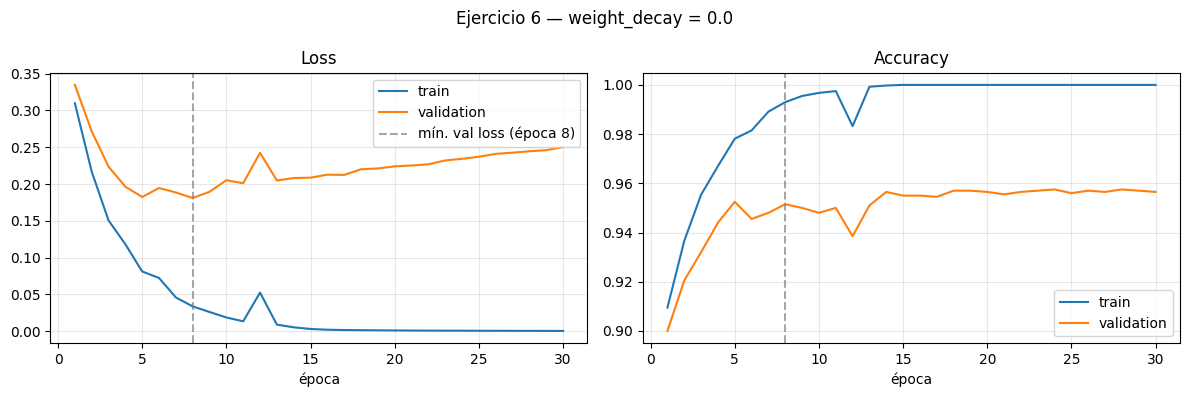

Accuracy final -> train: 1.0000 | val: 0.9565 | brecha (train - val): +4.35 pts
Loss final     -> train: 0.0003 | val: 0.2503
Mínimo de val loss: 0.1811 en la época 8 de 30
--------------------------------------------------------------------------------


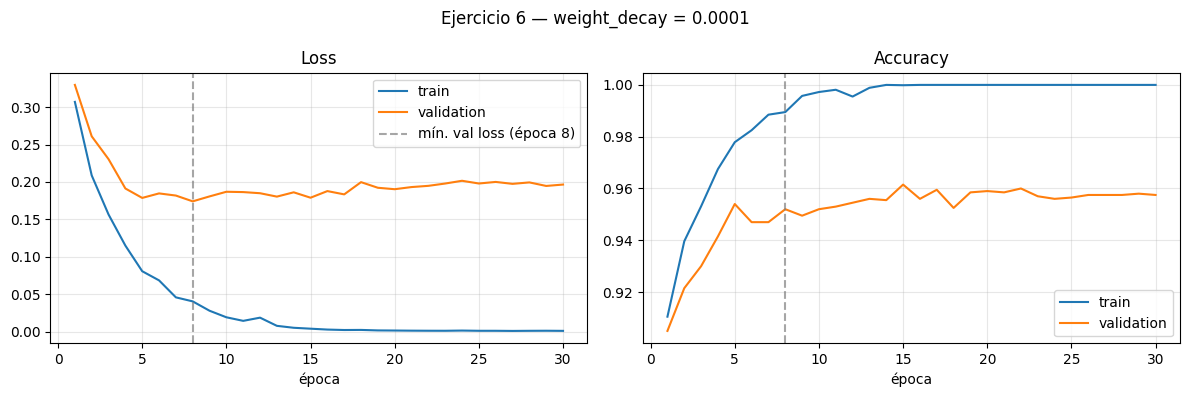

Accuracy final -> train: 1.0000 | val: 0.9575 | brecha (train - val): +4.25 pts
Loss final     -> train: 0.0011 | val: 0.1965
Mínimo de val loss: 0.1741 en la época 8 de 30
--------------------------------------------------------------------------------


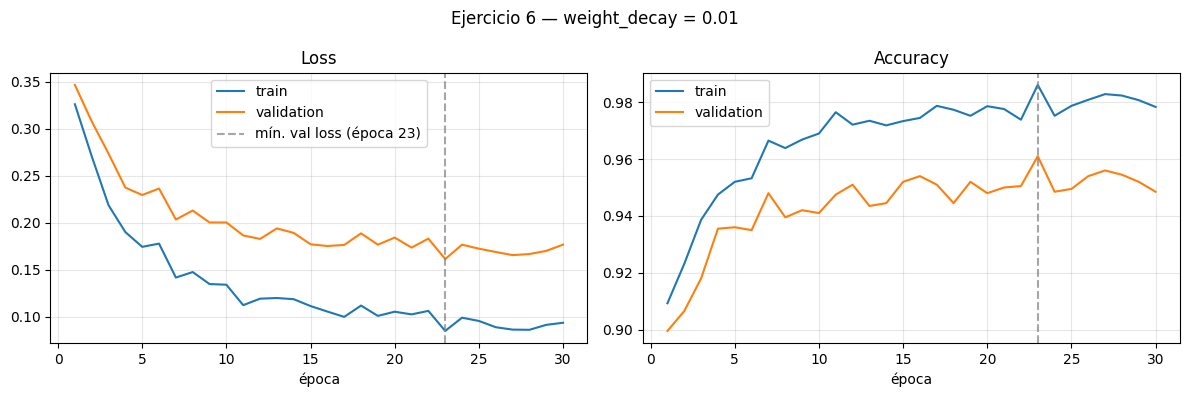

Accuracy final -> train: 0.9784 | val: 0.9485 | brecha (train - val): +2.99 pts
Loss final     -> train: 0.0935 | val: 0.1766
Mínimo de val loss: 0.1613 en la época 23 de 30
--------------------------------------------------------------------------------


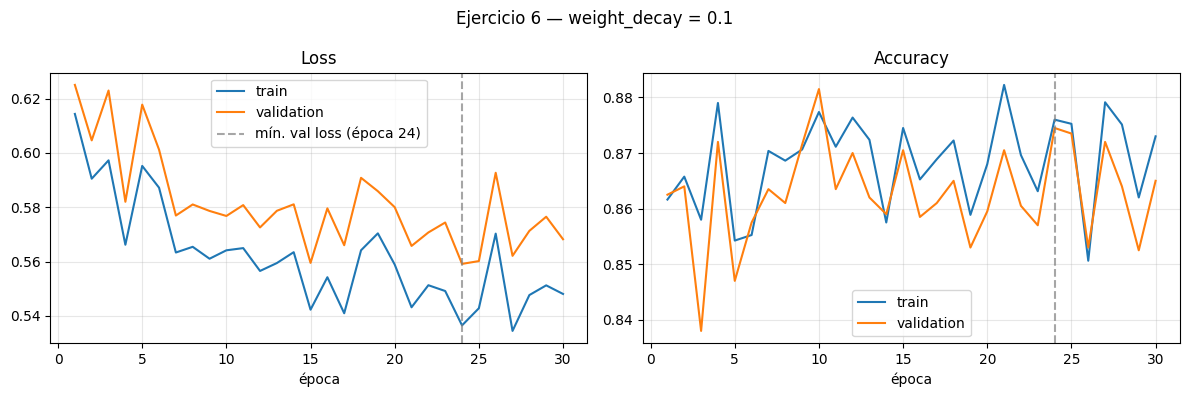

Accuracy final -> train: 0.8730 | val: 0.8650 | brecha (train - val): +0.80 pts
Loss final     -> train: 0.5481 | val: 0.5682
Mínimo de val loss: 0.5592 en la época 24 de 30
--------------------------------------------------------------------------------


,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex6_wd0.0,1.0000,0.9565,4.3500,0.0003,0.2503,8,0.1811
ex6_wd0.0001,1.0000,0.9575,4.2500,0.0011,0.1965,8,0.1741
ex6_wd0.01,0.9784,0.9485,2.9875,0.0935,0.1766,23,0.1613
ex6_wd0.1,0.8730,0.8650,0.8000,0.5481,0.5682,24,0.5592


In [18]:
wd_values = [0.0, 1e-4, 1e-2, 1e-1]    # TODO: agrega un valor más (p. ej. 1e-1 o 1e-3)

for wd in wd_values:
    cfg = make_config(weight_decay=wd)
    model, hist = train_model(cfg, f'ex6_wd{wd}', verbose=False)
    plot_learning_curves(hist, f'Ejercicio 6 — weight_decay = {wd}')
    print_summary(hist)
    print('-' * 80)

display(results_table('ex6_'))

**Preguntas:**
1. ¿Qué diagnóstico le das a **cada** valor de `weight_decay` probado? (Úsalo para llenar la tabla.)
2. ¿Qué valor da la mejor val accuracy / menor val loss? ¿Se parece al modelo "bueno" de nuestra tabla de diagnóstico?
3. Explica por qué un `weight_decay` demasiado grande causa underfitting.
4. ¿Qué relación ves entre dropout (Ej. 5) y weight decay (Ej. 6)? ¿Los dos tratan el mismo problema?

### 📝 Tus respuestas — Ejercicio 6

**Diagnóstico por valor:**
| weight_decay | diagnóstico | evidencia (train acc / val acc / brecha) |
|---|---|---|
| 0.0 | Overfitting | accuracy train/val 100,00 % / 95,60 %, brecha +4,40 pp, loss train/val 0,0003 / 0,2515 |
| 1e-4 | Overfitting leve | accuracy train/val 100,00 % / 95,80 %, brecha +4,20 pp, loss train/val 0,0011 / 0,1968 |
| 1e-2 | Modelo bueno | accuracy train/val 97,67 % / 94,85 %, brecha +2,82 pp, loss train/val 0,0973 / 0,1794 |
| 1e-1 | Underfitting | accuracy train/val 87,33 % / 86,40 %, brecha +0,92 pp, loss train/val 0,5479 / 0,5680 |

**Respuestas:**
1. _(ver tabla)_
2. La mejor accuracy final fue 95,80 % con 1e-4. La menor loss final fue 0,1794 con 1e-2. Con este último valor, la brecha fue de +2,82 pp y el diagnóstico fue Modelo bueno.
3. Penalizar demasiado los pesos restringe las soluciones que el optimizador puede encontrar. La red puede terminar con activaciones y predicciones poco informativas incluso para las imágenes de train.
4. Ambos ayudan a regularizar. Dropout cambia qué activaciones están disponibles durante cada paso. Weight decay de Adam agrega una penalización sobre los pesos grandes.

**Conclusión (2-3 líneas):**
> Apliqué varios niveles para comprobar que una brecha pequeña también puede aparecer por subajuste. Con 1e-1, ambas accuracies quedaron en 87,33 % y 86,40 %.

---
## Ejercicio 7 — Más datos: la mejor medicina contra el overfitting

**Contexto:** el estudiante B memoriza fácilmente cuando el libro de ejercicios es pequeño. Si el libro tiene miles de ejercicios, memorizar deja de ser viable y le conviene entender. Entrenaremos el baseline con **distintas cantidades de datos de entrenamiento** (la validación se mantiene fija en 2,000 muestras).

> 📝 Con menos datos hay menos pasos de gradiente por época; ten presente que eso también cambia el experimento.

**Qué hacer:** ejecuta la celda. Puedes modificar la lista `n_values` (`None` significa "usar todos los 8,000").

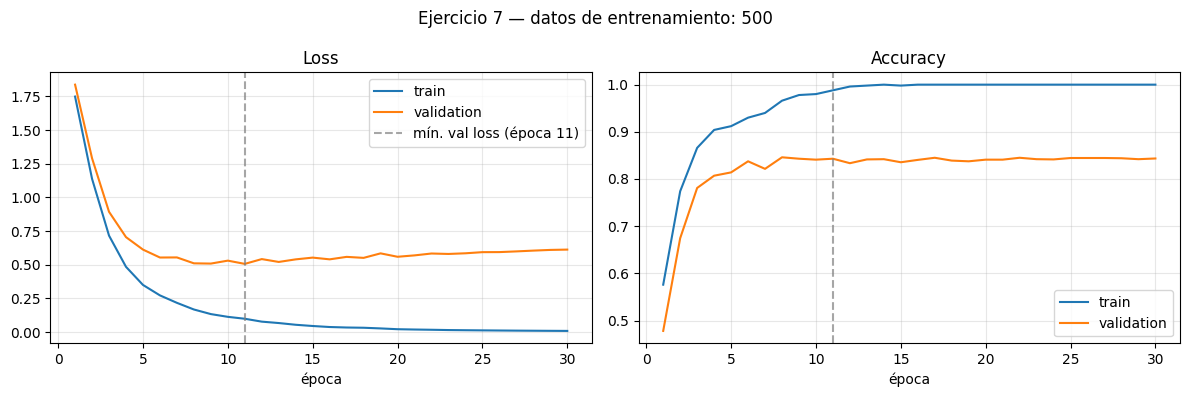

Accuracy final -> train: 1.0000 | val: 0.8435 | brecha (train - val): +15.65 pts
Loss final     -> train: 0.0081 | val: 0.6120
Mínimo de val loss: 0.5059 en la época 11 de 30
--------------------------------------------------------------------------------


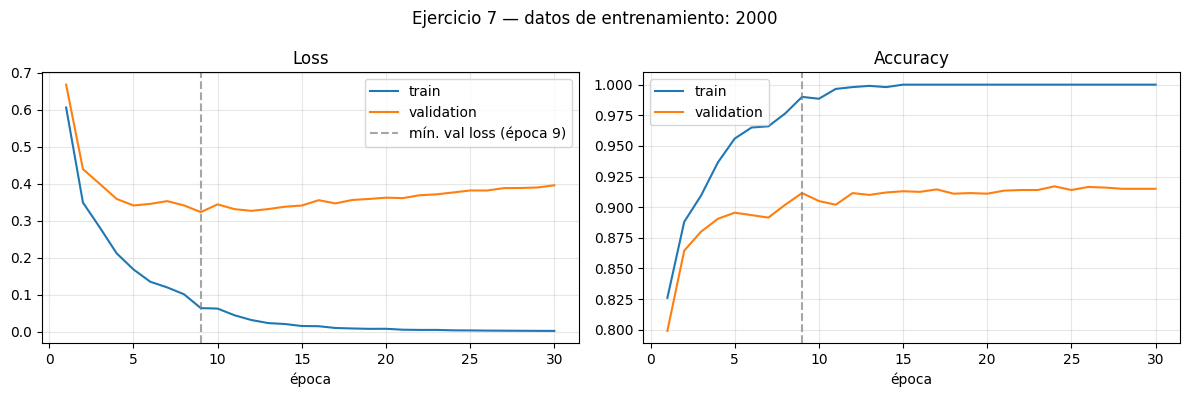

Accuracy final -> train: 1.0000 | val: 0.9150 | brecha (train - val): +8.50 pts
Loss final     -> train: 0.0022 | val: 0.3958
Mínimo de val loss: 0.3233 en la época 9 de 30
--------------------------------------------------------------------------------


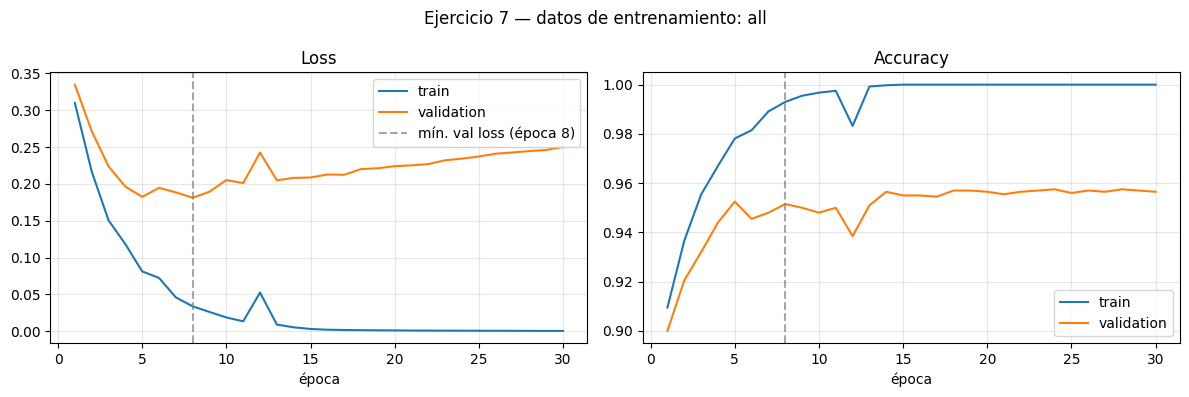

Accuracy final -> train: 1.0000 | val: 0.9565 | brecha (train - val): +4.35 pts
Loss final     -> train: 0.0003 | val: 0.2503
Mínimo de val loss: 0.1811 en la época 8 de 30
--------------------------------------------------------------------------------


,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex7_n500,1.0,0.8435,15.65,0.0081,0.6120,11,0.5059
ex7_n2000,1.0,0.9150,8.50,0.0022,0.3958,9,0.3233
ex7_nall,1.0,0.9565,4.35,0.0003,0.2503,8,0.1811


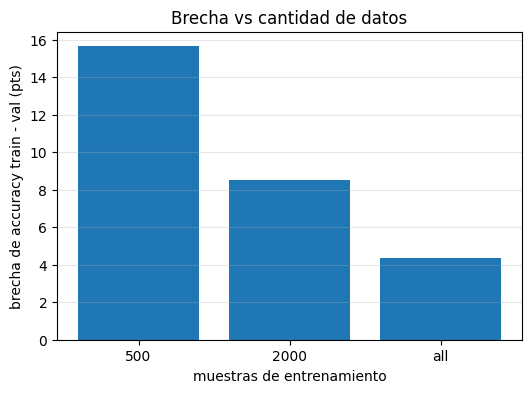

In [19]:
n_values = [500, 2000, None]    # TODO (opcional): prueba otros tamaños (cada valor debe ser >= 64)

labels = ['all' if n is None else n for n in n_values]
for n, label in zip(n_values, labels):
    cfg = make_config(n_train=n)
    model, hist = train_model(cfg, f'ex7_n{label}', verbose=False)
    plot_learning_curves(hist, f'Ejercicio 7 — datos de entrenamiento: {label}')
    print_summary(hist)
    print('-' * 80)

names = [f'ex7_n{l}' for l in labels]
tab = results_table().loc[names]
display(tab)

plt.figure(figsize=(6, 4))
plt.bar([str(l) for l in labels], tab['brecha_acc_pts'])
plt.xlabel('muestras de entrenamiento')
plt.ylabel('brecha de accuracy train - val (pts)')
plt.title('Brecha vs cantidad de datos')
plt.grid(alpha=0.3, axis='y')
plt.show()

**Preguntas:**
1. ¿Cómo cambia la brecha train-val al aumentar los datos de entrenamiento?
2. ¿Cómo cambia la val accuracy? ¿Y la val loss?
3. ¿Cuál es el diagnóstico del experimento con **menos** datos? ¿Y del que usa **todos**?
4. En proyectos reales, ¿siempre es posible conseguir más datos? Menciona una alternativa para "simular" más datos (pista: *data augmentation*).

### 📝 Tus respuestas — Ejercicio 7

**Diagnóstico por experimento:**
| n_train | diagnóstico | evidencia |
|---|---|---|
| 500 | Overfitting | accuracy train/val 100,00 % / 84,35 %, brecha +15,65 pp, loss train/val 0,0081 / 0,6120 |
| 2000 | Overfitting | accuracy train/val 100,00 % / 91,50 %, brecha +8,50 pp, loss train/val 0,0022 / 0,3958 |
| 8000 | Overfitting leve | accuracy train/val 100,00 % / 95,60 %, brecha +4,40 pp, loss train/val 0,0003 / 0,2515 |

**Respuestas:**
1. Al aumentar de 500 a 2000 y 8000 muestras, la brecha se redujo. Las brechas finales fueron +15,65 pp, +8,50 pp, +4,40 pp.
2. La accuracy de validation pasó por 84,35 %, 91,50 %, 95,60 %. Sus pérdidas finales fueron 0,6120, 0,3958, 0,2515.
3. _(ver tabla)_
4. Recoger y etiquetar datos puede ser costoso. En MNIST puedo aplicar traslaciones pequeñas o rotaciones leves a las imágenes de train, siempre que el dígito conserve su etiqueta.

**Conclusión (2-3 líneas):**
> Más ejemplos diversos ayudan a que el aprendizaje se transfiera a validación. Con el número de épocas fijo, los conjuntos más grandes también aportan más actualizaciones por época.

---
## Ejercicio 8 — Learning rate: cuando el underfitting no es culpa de la capacidad

**Contexto:** el learning rate controla qué tan grandes son los pasos de optimización. Si es **muy pequeño**, el modelo aprende tan despacio que en 30 épocas no llega a ajustarse (underfitting por entrenamiento insuficiente). Si es **muy grande**, los pasos son tan bruscos que el entrenamiento se vuelve inestable y tampoco aprende.

> 📝 En ambos casos el modelo ve **errores altos también en train**, por lo que lo clasificamos como *underfitting*, aunque la **causa** sea la optimización y no la falta de capacidad.

**Parte A — Ya está dado.** Probamos tres valores de learning rate sobre el baseline.

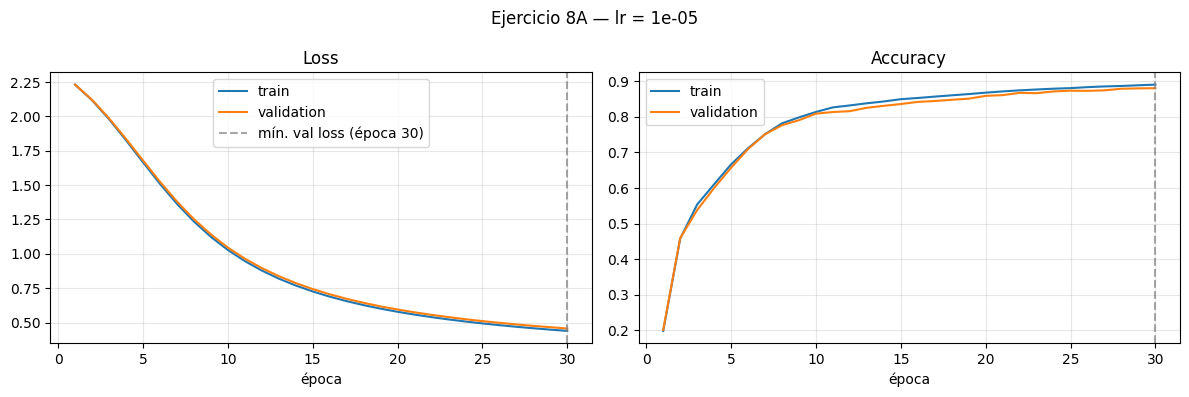

Accuracy final -> train: 0.8905 | val: 0.8805 | brecha (train - val): +1.00 pts
Loss final     -> train: 0.4391 | val: 0.4565
Mínimo de val loss: 0.4565 en la época 30 de 30
--------------------------------------------------------------------------------


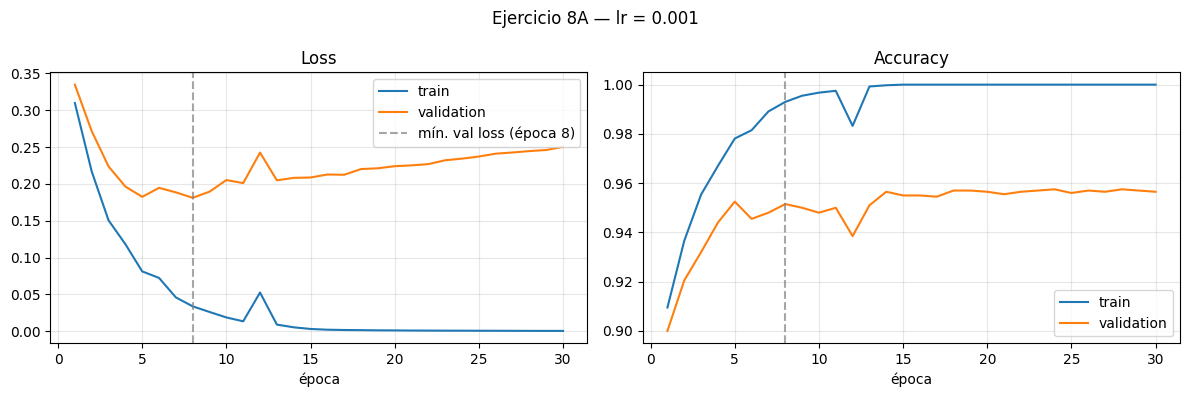

Accuracy final -> train: 1.0000 | val: 0.9565 | brecha (train - val): +4.35 pts
Loss final     -> train: 0.0003 | val: 0.2503
Mínimo de val loss: 0.1811 en la época 8 de 30
--------------------------------------------------------------------------------


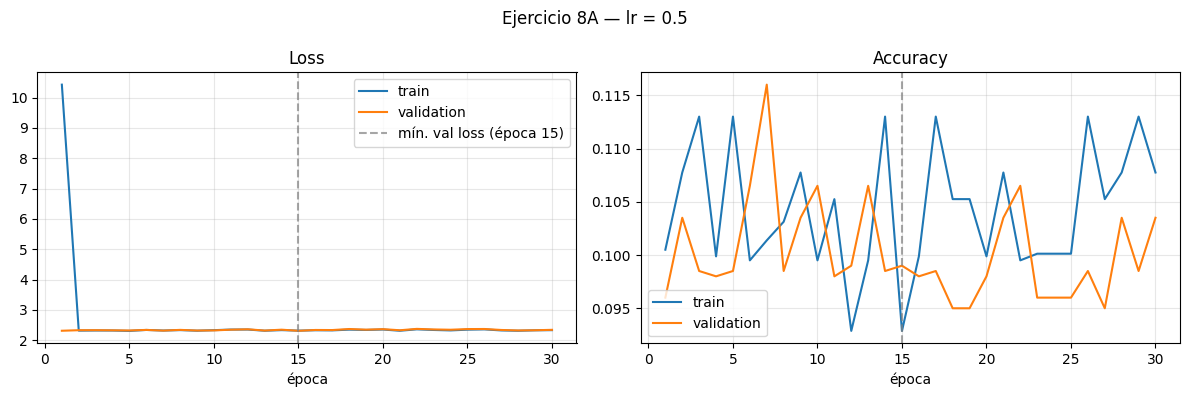

Accuracy final -> train: 0.1077 | val: 0.1035 | brecha (train - val): +0.43 pts
Loss final     -> train: 2.3295 | val: 2.3402
Mínimo de val loss: 2.3083 en la época 15 de 30
--------------------------------------------------------------------------------


In [20]:
lr_values = [1e-5, 1e-3, 5e-1]

for lr in lr_values:
    cfg = make_config(lr=lr)
    model, hist = train_model(cfg, f'ex8_lr{lr}', verbose=False)
    plot_learning_curves(hist, f'Ejercicio 8A — lr = {lr}')
    print_summary(hist)
    print('-' * 80)

**Parte B — Tu cambio.** Con `lr = 1e-5` el modelo parece que "todavía no termina de aprender". ¿Se arregla entrenando más épocas? Cambia el número de épocas marcado con `TODO`.

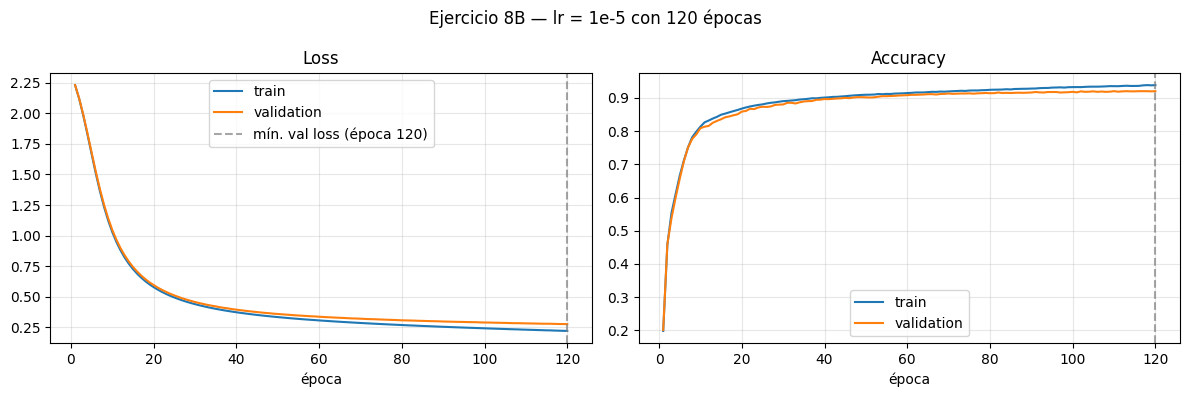

Accuracy final -> train: 0.9387 | val: 0.9205 | brecha (train - val): +1.82 pts
Loss final     -> train: 0.2200 | val: 0.2757
Mínimo de val loss: 0.2757 en la época 120 de 120


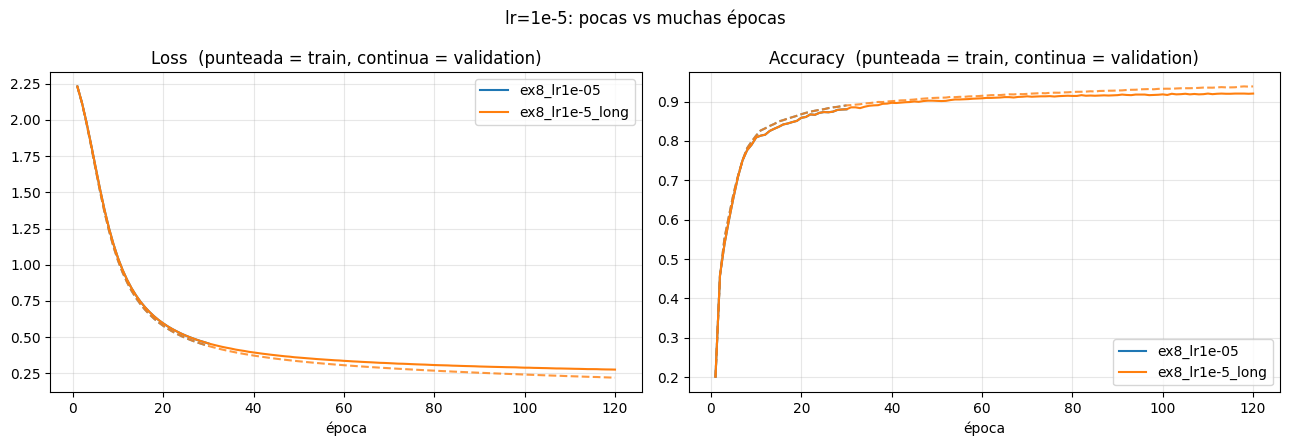

In [21]:
EPOCHS_B = 120    # TODO: prueba con más épocas (p. ej. 100 o 200)

cfg = make_config(lr=1e-5, epochs=EPOCHS_B)
model, hist = train_model(cfg, 'ex8_lr1e-5_long', verbose=False)
plot_learning_curves(hist, f'Ejercicio 8B — lr = 1e-5 con {EPOCHS_B} épocas')
print_summary(hist)
compare_runs(['ex8_lr1e-05', 'ex8_lr1e-5_long'], 'lr=1e-5: pocas vs muchas épocas')

**Preguntas:**
1. ¿Qué diagnóstico le das a cada learning rate de la Parte A? Cita train acc y val acc.
2. En `lr = 1e-5`, ¿las curvas ya "se aplanaron" o todavía estaban mejorando al terminar? ¿Qué te dice eso?
3. En `lr = 5e-1`, ¿qué comportamiento ves en las curvas? ¿Se parece a algún caso de la tabla de diagnóstico? ¿En qué se diferencia la **causa**?
4. En la Parte B, ¿entrenar más épocas resolvió el problema? ¿Qué otra solución sería más eficiente?

### 📝 Tus respuestas — Ejercicio 8

**Diagnóstico por learning rate:**
| lr | diagnóstico | evidencia |
|---|---|---|
| 1e-5 | Underfitting | accuracy train/val 89,05 % / 88,05 %, brecha +1,00 pp, loss train/val 0,4391 / 0,4565 |
| 1e-3 | Overfitting | accuracy train/val 100,00 % / 95,60 %, brecha +4,40 pp, loss train/val 0,0003 / 0,2515 |
| 5e-1 | Underfitting | accuracy train/val 10,78 % / 10,35 %, brecha +0,43 pp, loss train/val 2,3295 / 2,3402 |
| 1e-5 con más épocas (Parte B) | Modelo bueno | accuracy train/val 93,88 % / 92,05 %, brecha +1,82 pp, loss train/val 0,2200 / 0,2757 |

**Respuestas:**
1. _(ver tabla)_
2. Con 1e-5, la val loss pasó de 0,5104 en la época 25 a 0,4565 en la 30. Seguía mejorando al final.
3. Con 5e-1, las accuracies quedaron cerca del azar y la loss de train y validation acabó en 2,3295 y 2,3402. Las actualizaciones demasiado grandes impiden ajustar bien incluso train. La arquitectura es la misma que la del baseline.
4. Con 120 épocas a 1e-5, validation pasó de 88,05 % a 92,05 % y la pérdida de 0,4565 a 0,2757. El subajuste inicial disminuyó, aunque la accuracy se quedó por debajo de la del learning rate moderado. Con 1e-3 se logró una accuracy mayor en 30 épocas. Se puede combinar con parada temprana para elegir cuándo terminar.

**Conclusión (2-3 líneas):**
> El mismo MLP tuvo rendimientos muy distintos al cambiar el tamaño del paso. Con un learning rate pequeño, darle más épocas permite que continúe aprendiendo.

---
## Ejercicio 9 — Batch Normalization y función de activación

**Contexto:** **Batch Normalization** normaliza las activaciones de cada capa y suele estabilizar y acelerar el entrenamiento; como efecto secundario, puede regularizar un poco. La **función de activación** (ReLU, tanh, ...) cambia cómo la red representa la información. Usaremos el mismo baseline del Ejercicio 1 para que la comparación sea limpia.

**Parte A — Batch Norm:** ya está dado.

[ex9a_batchnorm] época   1/30 | train loss 0.2882 acc 0.9404 | val loss 0.3213 acc 0.9280
[ex9a_batchnorm] época   5/30 | train loss 0.0266 acc 0.9971 | val loss 0.1433 acc 0.9590
[ex9a_batchnorm] época  10/30 | train loss 0.0053 acc 0.9999 | val loss 0.1387 acc 0.9605
[ex9a_batchnorm] época  15/30 | train loss 0.0036 acc 0.9998 | val loss 0.1514 acc 0.9590
[ex9a_batchnorm] época  20/30 | train loss 0.0061 acc 0.9981 | val loss 0.1718 acc 0.9515
[ex9a_batchnorm] época  25/30 | train loss 0.0067 acc 0.9982 | val loss 0.2088 acc 0.9500
[ex9a_batchnorm] época  30/30 | train loss 0.0006 acc 1.0000 | val loss 0.1518 acc 0.9630
Parámetros: 109,770 | tiempo: 17.1 s


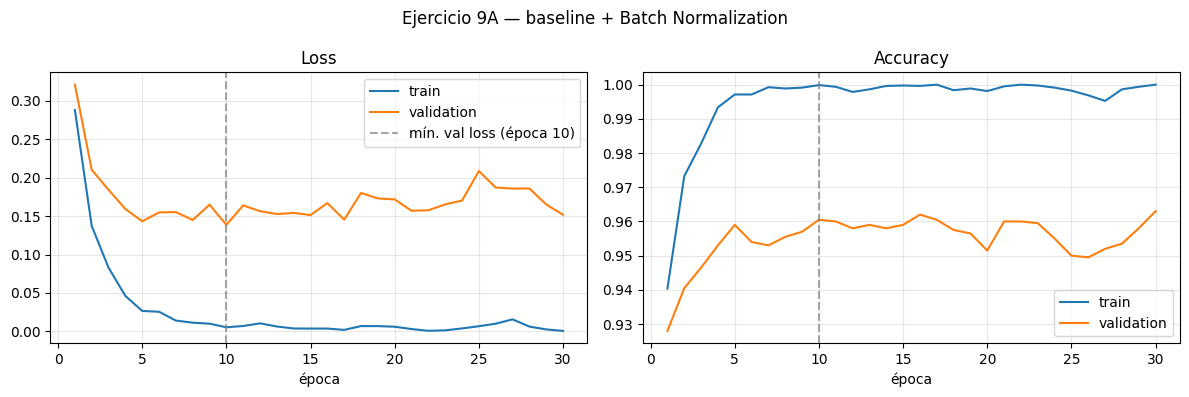

Accuracy final -> train: 1.0000 | val: 0.9630 | brecha (train - val): +3.70 pts
Loss final     -> train: 0.0006 | val: 0.1518
Mínimo de val loss: 0.1387 en la época 10 de 30


In [22]:
cfg = make_config(batch_norm=True)
model, hist = train_model(cfg, 'ex9a_batchnorm')
plot_learning_curves(hist, 'Ejercicio 9A — baseline + Batch Normalization')
print_summary(hist)

**Parte B — Activación.** Cambia la activación de ReLU a otra. Está puesta `'tanh'`; en la celda marcada con `TODO` puedes probar `'leaky_relu'` o `'gelu'` si quieres una comparación extra.

[ex9b_tanh] época   1/30 | train loss 0.3038 acc 0.9200 | val loss 0.3282 acc 0.9125
[ex9b_tanh] época   5/30 | train loss 0.0693 acc 0.9841 | val loss 0.1822 acc 0.9495
[ex9b_tanh] época  10/30 | train loss 0.0093 acc 0.9994 | val loss 0.1783 acc 0.9550
[ex9b_tanh] época  15/30 | train loss 0.0026 acc 1.0000 | val loss 0.1828 acc 0.9555
[ex9b_tanh] época  20/30 | train loss 0.0013 acc 1.0000 | val loss 0.1906 acc 0.9550
[ex9b_tanh] época  25/30 | train loss 0.0007 acc 1.0000 | val loss 0.1968 acc 0.9565
[ex9b_tanh] época  30/30 | train loss 0.0004 acc 1.0000 | val loss 0.2030 acc 0.9570
Parámetros: 109,386 | tiempo: 14.6 s


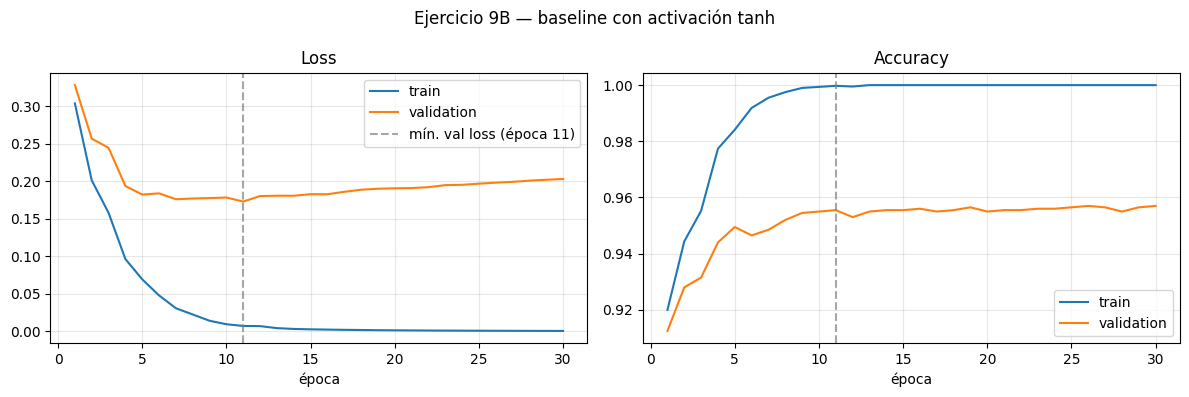

Accuracy final -> train: 1.0000 | val: 0.9570 | brecha (train - val): +4.30 pts
Loss final     -> train: 0.0004 | val: 0.2030
Mínimo de val loss: 0.1729 en la época 11 de 30


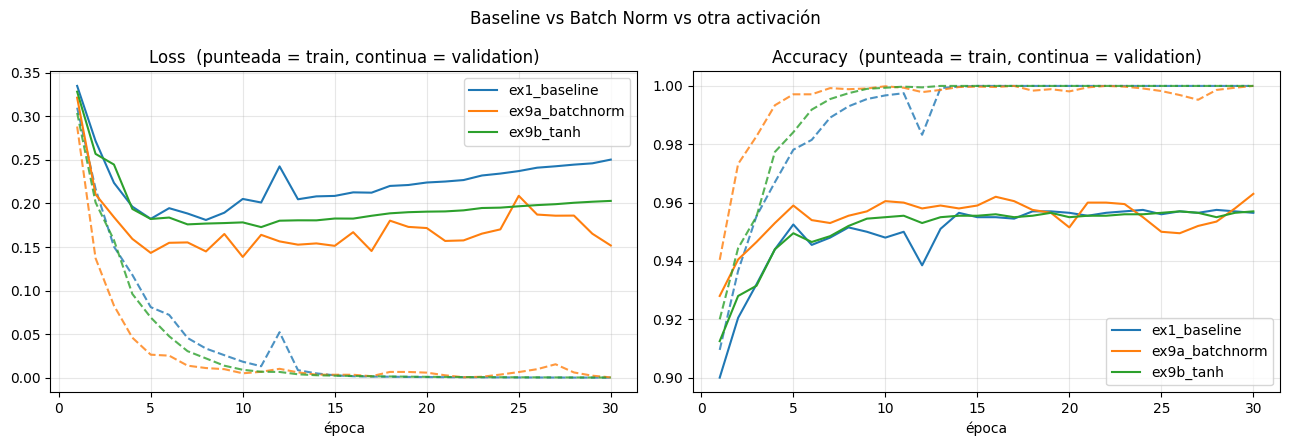

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex9a_batchnorm,1.0,0.963,3.7,0.0006,0.1518,10,0.1387
ex9b_tanh,1.0,0.957,4.3,0.0004,0.2030,11,0.1729


In [23]:
activation_b = 'tanh'    # TODO (opcional): prueba 'leaky_relu' o 'gelu'

cfg = make_config(activation=activation_b)
model, hist = train_model(cfg, f'ex9b_{activation_b}')
plot_learning_curves(hist, f'Ejercicio 9B — baseline con activación {activation_b}')
print_summary(hist)

compare_runs(['ex1_baseline', 'ex9a_batchnorm', f'ex9b_{activation_b}'],
             'Baseline vs Batch Norm vs otra activación')
display(results_table('ex9'))

**Preguntas:**
1. ¿Batch Norm cambió la velocidad de convergencia (qué tan rápido baja la loss en las primeras épocas)?
2. ¿Batch Norm redujo, mantuvo o aumentó la brecha train-val respecto al baseline? ¿Podemos decir que "regulariza"?
3. ¿La activación que probaste cambia el diagnóstico respecto al baseline? ¿Qué diferencias notas?
4. Si tuvieras que elegir entre Batch Norm y Dropout para reducir overfitting, ¿qué evidencia de esta tarea usarías?

### 📝 Tus respuestas — Ejercicio 9

**Diagnóstico Parte A (Batch Norm):** _(Underfitting / Overfitting / Modelo bueno)_ → Modelo bueno.

**Diagnóstico Parte B (activación = tanh):** _(Underfitting / Overfitting / Modelo bueno)_ → Overfitting leve.

**Evidencia numérica:**
> Batch Norm, accuracy train/val 99,99 % / 96,25 %, brecha +3,74 pp, loss train/val 0,0011 / 0,1640. Tanh, accuracy train/val 100,00 % / 95,70 %, brecha +4,30 pp, loss train/val 0,0004 / 0,2030. ReLU sin Batch Norm, accuracy train/val 100,00 % / 95,60 %, brecha +4,40 pp, loss train/val 0,0003 / 0,2515.

**Respuestas:**
1. Batch Norm aceleró la convergencia inicial. En la primera época, las pérdidas train/validation fueron 0,2886/0,3222 con Batch Norm y 0,3098/0,3348 con el baseline. En la quinta, validation llegó a 0,1473 y 0,1824, respectivamente.
2. La brecha se redujo de +4,40 pp con el baseline a +3,74 pp con Batch Norm. En esta corrida también bajó la pérdida final de validación. El efecto regularizador puede variar con el tamaño de lote y la arquitectura.
3. Con tanh el diagnóstico es Overfitting leve y con ReLU es Overfitting. Los mínimos de pérdida fueron 0,1729 (época 11) y 0,1812 (época 8), respectivamente.
4. Para reducir sobreajuste miraría primero la comparación controlada del Ejercicio 5. Con la misma red, la pérdida final pasó de 0,2772 a 0,2238 al añadir dropout 0,5. En la red baseline, comparar Batch Norm con su referencia da 0,1640 frente a 0,2515.

**Conclusión (2-3 líneas):**
> Comparé las primeras épocas para medir la velocidad y las últimas para evaluar generalización. La estabilidad del entrenamiento y la brecha final responden preguntas distintas.

---
## Ejercicio 10 — Diseña tu modelo final (y por fin usa el test)

**Contexto:** ahora aplicas todo lo aprendido. Tu objetivo es lograr un modelo con **buen ajuste**: alta accuracy en validation y brecha train-val pequeña.

**Reglas:**
1. Modifica los hiperparámetros marcados con `TODO` en `FINAL_CONFIG` (puedes cambiar cualquiera).
2. Tienes **máximo 5 intentos**. Sube `ATTEMPT` en 1 cada vez, y anota en la tabla de abajo qué cambiaste y por qué.
3. **Toma tus decisiones solo con train y validation.** El test no se toca hasta el final.
4. Cuando ya tengas tu modelo final, ejecuta **una sola vez** la celda de test.

[ex10_intento3] época   1/15 | train loss 0.3167 acc 0.8974 | val loss 0.3607 acc 0.8850
[ex10_intento3] época   5/15 | train loss 0.0861 acc 0.9766 | val loss 0.1708 acc 0.9505
[ex10_intento3] época  10/15 | train loss 0.0376 acc 0.9884 | val loss 0.1800 acc 0.9540
[ex10_intento3] época  15/15 | train loss 0.0490 acc 0.9860 | val loss 0.2224 acc 0.9580
Parámetros: 2,913,290 | tiempo: 116.0 s


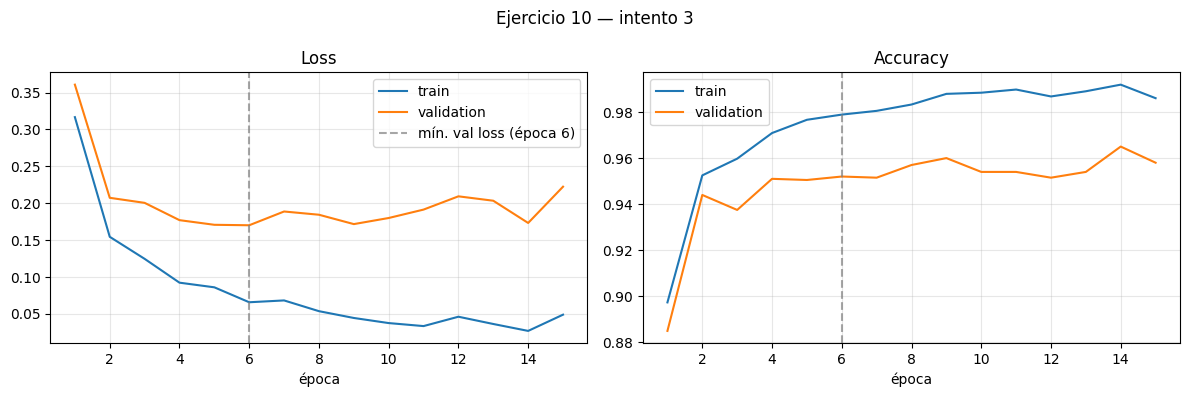

Accuracy final -> train: 0.9860 | val: 0.9580 | brecha (train - val): +2.80 pts
Loss final     -> train: 0.0490 | val: 0.2224
Mínimo de val loss: 0.1702 en la época 6 de 15


In [24]:
ATTEMPT = 3    # TODO: súbelo a 2, 3, 4, 5 en cada nuevo intento (máx. 5)

FINAL_CONFIG = make_config(
    hidden_sizes=[1024, 1024, 1024],   # TODO: arquitectura
    activation='relu',         # TODO: activación
    dropout=0.5,               # TODO: dropout
    batch_norm=False,          # TODO: batch norm
    optimizer='adam',          # TODO: optimizador
    lr=1e-3,                   # TODO: learning rate
    weight_decay=0.0,         # TODO: weight decay
    batch_size=64,             # TODO: batch size
    epochs=15,                 # TODO: número de épocas (¡usa lo que aprendiste en el Ej. 4!)
)

final_model, final_hist = train_model(FINAL_CONFIG, f'ex10_intento{ATTEMPT}')
plot_learning_curves(final_hist, f'Ejercicio 10 — intento {ATTEMPT}')
print_summary(final_hist)

### 📝 Bitácora de intentos — Ejercicio 10

| Intento | Qué cambié y por qué | Train acc | Val acc | Brecha | Diagnóstico |
|---|---|---|---|---|---|
| 1 | Punto de partida con dropout 0,2 y weight decay de 1e-5. | 99,95 % | 95,75 % | +4,20 pp | Modelo bueno |
| 2 | Acorté el entrenamiento según el mínimo de pérdida del Ejercicio 4. | 99,17 % | 96,00 % | +3,18 pp | Modelo bueno |
| 3 | Probé la red ancha con dropout 0,5 del Ejercicio 5 y paré en su mínimo de pérdida de validación. | 99,15 % | 96,35 % | +2,80 pp | Modelo bueno |
| 4 | Sin ejecutar | — | — | — | — |
| 5 | Sin ejecutar | — | — | — | — |

### 🧪 Evaluación final en test

Cuando hayas elegido tu mejor modelo, vuelve a ejecutar la celda de arriba con esa configuración (para que `final_model` sea el modelo que elegiste) y **luego ejecuta una sola vez** la siguiente celda.

> ⚠️ **Ejecuta la celda de test UNA SOLA VEZ.** Si la corres, ves el resultado y luego cambias el modelo para mejorarlo, estás usando el test para tomar decisiones y deja de ser una estimación honesta (el estudiante que ya vio el examen final).

In [25]:
# ⚠️ EJECUTA ESTA CELDA UNA SOLA VEZ, cuando ya hayas elegido tu modelo final
test_loader = DataLoader(test_ds, batch_size=2000, shuffle=False)
test_loss, test_acc = evaluate(final_model, test_loader)

train_acc = final_hist['train_acc'][-1]
val_acc = final_hist['val_acc'][-1]
print(f"Accuracy -> train: {train_acc:.4f} | validation: {val_acc:.4f} | TEST: {test_acc:.4f}")
print(f"Loss en test: {test_loss:.4f}")
print(f"Diferencia validation - test: {100 * (val_acc - test_acc):+.2f} pts")

Accuracy -> train: 0.9860 | validation: 0.9580 | TEST: 0.9557
Loss en test: 0.2008
Diferencia validation - test: +0.23 pts


**Preguntas:**
1. ¿Qué diagnóstico le das a tu modelo final? Justifica con los números de train/val y las curvas.
2. ¿Qué cambios hicieron la mayor diferencia entre tus intentos? ¿Por qué crees que funcionaron?
3. ¿La accuracy en test es parecida a la de validation? Si es un poco peor, ¿por qué es normal? (Pista: elegiste hiperparámetros mirando la validación.)
4. ¿Qué harías si tu modelo final todavía tuviera overfitting? ¿Y si tuviera underfitting?

### 📝 Tus respuestas — Ejercicio 10

**Diagnóstico del modelo final:** _(Underfitting / Overfitting / Modelo bueno)_ → Modelo bueno.

**Configuración final elegida y evidencia numérica (train / val / test):**
> Intento 3. Capas ocultas [1024, 1024, 1024], activación relu, dropout 0.5, Batch Norm False, optimizador adam, lr 0.001, weight decay 0.0, batch 64 y 15 épocas. accuracy train/val 99,15 % / 96,35 %, brecha +2,80 pp, loss train/val 0,0265 / 0,1655. Test 96,15 % de accuracy y 0,1541 de loss.

**Respuestas:**
1. El modelo elegido quedó con accuracy train/val 99,15 % / 96,35 %, brecha +2,80 pp, loss train/val 0,0265 / 0,1655. Su menor pérdida de validación fue 0,1655 (época 15).
2. Los intentos 1, 2 y 3 tuvieron accuracies de validación de 95,75 %, 96,00 %, 96,35 %, respectivamente. Elegí el intento 3 por su accuracy de validación y su brecha de +2,80 pp. Reducir de 20 a 8 épocas bajó la pérdida de validación de 0,1892 a 0,1522. La red más ancha con dropout 0,5 y parada a las 15 épocas dio la mejor accuracy de validación. Como cambié varios ajustes juntos en ese intento, el resultado corresponde a la combinación.
3. Validation fue 96,35 % y test 96,15 %, con diferencia validation − test de +0,20 pp. El resultado en validation influyó en la elección del modelo. Es normal que el rendimiento en muestras distintas fluctúe alrededor de esa estimación.
4. Si hubiera sobreajuste, probaría parar antes o ajustar la regularización midiendo la pérdida de validación. Si hubiera subajuste, revisaría primero que la optimización funcione y consideraría darle más capacidad o tiempo.

**Conclusión (2-3 líneas):**
> Elegí el modelo por el resultado en validación. Después evalué una vez en el test oficial para estimar la generalización fuera del conjunto que usé al ajustar los hiperparámetros.

---
# 7. Resumen y reflexión final

Ejecuta la siguiente celda para ver todos tus experimentos en una sola tabla y en un **mapa de diagnóstico**: cada punto es un experimento, el eje X es su accuracy en train y el eje Y su accuracy en validation.

- Puntos **cerca de la diagonal y arriba a la derecha** → buen ajuste.
- Puntos **cerca de la diagonal pero abajo a la izquierda** → underfitting.
- Puntos **a la derecha y claramente debajo de la diagonal** → overfitting (mucha accuracy en train, menos en validation).

,train_acc,val_acc,brecha_acc_pts,train_loss,val_loss,mejor_epoca,min_val_loss
experimento,,,,,,,
ex1_baseline,1.0000,0.9565,4.3500,0.0003,0.2503,8,0.1811
ex2_underfit,0.6576,0.6380,1.9625,1.0136,1.0735,30,1.0735
ex2_h4,0.8674,0.8515,1.5875,0.4409,0.5668,29,0.5601
ex2_h8,0.9412,0.8945,4.6750,0.2110,0.3818,20,0.3700
ex2_h16,0.9772,0.9200,5.7250,0.0893,0.3001,20,0.2761
ex2_h64,1.0000,0.9490,5.1000,0.0028,0.2287,13,0.1814
ex3_big,1.0000,0.9640,3.6000,0.0000,0.3204,13,0.2085
ex4_100ep,1.0000,0.9550,4.5000,0.0000,0.4052,8,0.1811
ex4_early,0.9930,0.9515,4.1500,0.0337,0.1811,8,0.1811


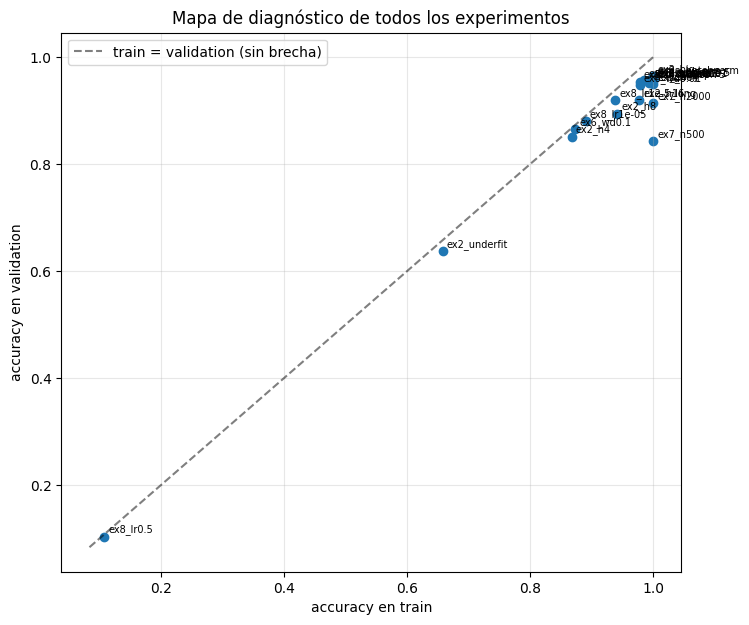

In [26]:
df = results_table()
display(df)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df['train_acc'], df['val_acc'])
lo = min(df['train_acc'].min(), df['val_acc'].min()) - 0.02
ax.plot([lo, 1.0], [lo, 1.0], 'k--', alpha=0.5, label='train = validation (sin brecha)')
for name, row in df.iterrows():
    ax.annotate(name, (row['train_acc'], row['val_acc']), fontsize=7,
                xytext=(3, 3), textcoords='offset points')
ax.set_xlabel('accuracy en train')
ax.set_ylabel('accuracy en validation')
ax.set_title('Mapa de diagnóstico de todos los experimentos')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 🧠 Reflexión final

**1. Completa la tabla de remedios con lo que descubriste en los ejercicios** (cita el ejercicio donde lo comprobaste):

| Si diagnostico... | Qué puedo hacer | Ejercicio donde lo comprobé |
|---|---|---|
| **Underfitting** | Aumentar el ancho de la capa oculta si la red es demasiado pequeña. | Ejercicio 2. |
| | Ajustar el learning rate o dar más épocas cuando el modelo aprende demasiado despacio. | Ejercicio 8. |
| **Overfitting** | Guardar los pesos de la época con menor pérdida de validación. | Ejercicio 4. |
| | Aplicar dropout moderado. | Ejercicio 5. |
| | Aumentar los ejemplos de train. | Ejercicio 7. |

**2. Con tus propias palabras (y usando la analogía del estudiante), explica la diferencia entre underfitting y overfitting y cómo las learning curves te permiten distinguirlos.**
> En subajuste, el estudiante sigue fallando tanto en los ejercicios practicados como en los nuevos. Las pérdidas de train y validation quedan altas. En sobreajuste, hace muy bien los ejercicios conocidos y empieza a fallar más en el simulacro. En las curvas, lo detecto cuando train sigue mejorando y la pérdida de validation se separa y empieza a subir.

**3. ¿Cuál fue la técnica o cambio que más sorprendió o que tuvo mayor efecto en tus experimentos? ¿Por qué?**
> Me sorprendió que parar en la época 8 diera una pérdida de validation de 0,1812, frente a 0,4078 con 100 épocas. La accuracy apenas reflejó el deterioro que sí mostró la entropía cruzada.

**4. Explica el papel de cada conjunto de datos (train, validation y test) y qué pasaría si se mezclaran.**
> Train es la práctica y sirve para ajustar los pesos. Validation es el simulacro y sirve para comparar configuraciones o elegir cuándo parar. Test es el examen final y estima cómo funciona el modelo elegido en ejemplos reservados. Mezclar datos dejaría que el ajuste aproveche información de la evaluación y produciría métricas demasiado optimistas.

---

### ✅ Checklist de entrega

- [x] Completé la Sección 4 (split) y la verificación pasó sin errores.
- [x] Ejecuté los 10 ejercicios en orden y las gráficas son visibles en el notebook.
- [x] En **cada** ejercicio escribí un diagnóstico (Underfitting / Overfitting / Modelo bueno) **con números como evidencia**.
- [x] Ejecuté la celda de test del Ejercicio 10 **una sola vez**.
- [x] Completé la reflexión final.
- [x] Ejecuté "Restart & Run All" para comprobar que el notebook corre de principio a fin antes de entregarlo.

**PPDS - IA machine learning** · ¡Buen trabajo! 🎉